# Can pauses help us find Whisper’s word errors?

Whisper turns speech into text. This notebook checks whether long pauses in TORGO recordings tend to fall near words that Whisper gets wrong. It also tests whether showing those pauses to a text editor helps it correct the transcript.

**Completed grouped experiment.** Showing the editor real pauses did not reliably improve this recognizer. Among 624 dysarthric recordings, it removed five of 775 errors. Among the 27 recordings with a distinct equal-budget random control, untouched ASR and visible real markers both gave 198 errors. Random locations gave 200. The 95% interval for the real-location advantage was −1.10 to +2.56 WER percentage points. On the 50 marked recordings, hiding the marker in the same windows gave 258 errors and showing it gave 261.

These figures come from the completed November 9 full run. Its exact predictions and live replies are in [the completed archive](iciss_reviewed_full.zip). The November 11 acoustic archive reproduces the ASR predictions and localization tables. Its export ends before any correction results. Saved execution outputs below illustrate the eight-recording validation smoke test.

## Table of contents

1. [Set up the notebook](#section-1)
   - [Check the Task 2 files](#training-files)
2. [Choose recordings and set the pause rule](#section-2)
   - [Load the selected Whisper model](#adapted-model)
   - [Load the TORGO recordings](#torgo-audio)
   - [Choose how long a pause must be](#pause-length)
3. [Compare the two Whisper models](#section-3)
   - [Read the word error rates](#word-error-rate)
4. [Compare word times in the two transcripts](#section-4)
5. [Add pause markers to the text](#section-5)
6. [Test whether pauses are near errors](#section-6)
   - [Compare pauses with random markers](#random-comparison)
   - [Count recordings with errors](#recording-errors)
7. [Try editing the words near a pause](#section-7)
   - [Choose which words the editor sees](#edit-windows)
   - [Put the edits back into the transcript](#apply-edits)
8. [Compare errors before and after editing](#section-8)
   - [Compare the three editing methods](#edit-results)
9. [Review the earlier study and save results](#section-9)
   - [Save the results as a ZIP](#export)

### Before you run it on Kaggle

1. Attach your Task 2 dataset and copy its path. Paste it into `INPUT_PATH` in the first code cell.
2. Turn on **Internet** and select **a T4 GPU**. The full Task 2 ZIP includes the selected model. For a metadata-only input, enable a read-capable `HF_TOKEN` for the private model in **Add-ons → Secrets**. For live editing, also enable `GROQ_API_KEY`.
3. Choose **Run All** for the full test. For a quick check, set `SMOKE = True` before running. It uses a few validation recordings and skips live editor calls.

The saved tables and plots are examples from a local smoke test. Its editor echoed the input text. Running the full notebook produces results on the held-out test recordings.

<a id="section-1"></a>

## 1. Set up the notebook

Paste the Kaggle path into `INPUT_PATH` in the next cell. Use the folder with the six Task 2 files, the folder directly above `iciss_grouped_task2/`, or the metadata ZIP itself.

In [1]:
# Paste the Kaggle path for your Task 2 input here.
INPUT_PATH = "/kaggle/input/datasets/menhazabdin/iciss-grouped-task2"

from pathlib import Path, PurePosixPath
from uuid import uuid4
import time
import os, hashlib, zipfile, json, io, re, math, itertools, random, shutil, sys, platform, gc
from collections import Counter
from dataclasses import dataclass
from datetime import datetime, timezone
from importlib.metadata import version
from IPython.display import display, Image

SMOKE = os.getenv("ICISS_EVAL_SMOKE", "0") == "1"  # default False
# SMOKE=True
RUN_CORRECTION = os.getenv("ICISS_CORRECTION", "1") == "1"  # default True
MODEL_REPO = "Menhaz/whisper-tiny-torgo-grouped-iciss"
MODEL_REVISION = "958b6c10786e6cf8e6f1dae03ad1db5d407c3339"
PRIVATE_BACKUP_REPO = os.getenv("ICISS_BACKUP_REPO", "")
OUTPUT = Path(
    os.getenv(
        "ICISS_EVAL_OUTPUT",
        "/kaggle/working" if Path("/kaggle/working").is_dir() else "iciss_evaluation_outputs",
    )
)

In [2]:
# Start a new run and show its settings.
RUN_ID = datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%SZ") + "_" + uuid4().hex[:10]
ASR_BATCH, SHARD_SIZE, SEED = (2 if SMOKE else 8), 32, 0
N_PERM, N_BOOT = (64, 128) if SMOKE else (2000, 5000)
print(
    "New evaluation:",
    RUN_ID,
    "|",
    "development smoke test" if SMOKE else "full held-out evaluation",
)
print("Fine-tuned model:", MODEL_REPO, "@", MODEL_REVISION[:12])

New evaluation: 20261112T053554Z_7b6c322ff5 | full held-out evaluation
Fine-tuned model: Menhaz/whisper-tiny-torgo-grouped-iciss @ 958b6c10786e


In [3]:
# Check dependencies for the selected mode and set up table and figure display.
import subprocess
from packaging.requirements import Requirement
from importlib.metadata import PackageNotFoundError

requirements = [
    "jiwer==4.0.0",
    "pandas",
    "numpy",
    "scipy",
    "scikit-learn",
    "matplotlib",
    "pyarrow",
    "psutil",
    "requests",
    "tqdm",
]
os.environ["CUDA_VISIBLE_DEVICES"] = os.environ.get("CUDA_VISIBLE_DEVICES", "0").split(",")[0]
requirements.extend(["transformers==4.57.6", "soundfile>=0.12"])
for specification in requirements:
    req = Requirement(specification)
    try:
        installed = version(req.name) in req.specifier
    except PackageNotFoundError:
        installed = False
    if not installed:
        subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", specification])

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
gradio-client 2.7.2 requires huggingface-hub<3.0,>=1.16.0, but you have huggingface-hub 0.36.2 which is incompatible.
gradio 6.30.0 requires huggingface-hub<3.0,>=1.16.0, but you have huggingface-hub 0.36.2 which is incompatible.
gradio 6.30.0 requires pillow<13.0,>=8.0, but you have pillow 13.0.0 which is incompatible.
diffusers 0.42.0 requires huggingface-hub<3.0,>=1.32.0, but you have huggingface-hub 0.36.2 which is incompatible.


Check the library that finds word times.

In [4]:
probe = [
    sys.executable,
    "-c",
    "import ctc_segmentation; from importlib.metadata import version; assert version('ctc-segmentation')=='1.7.4'",
]
if subprocess.run(probe, capture_output=True).returncode:
    subprocess.check_call(
        [sys.executable, "-m", "pip", "install", "-q", "cython", "setuptools", "wheel"]
    )
    subprocess.check_call(
        [
            sys.executable,
            "-m",
            "pip",
            "install",
            "-q",
            "--no-build-isolation",
            "--no-deps",
            "--force-reinstall",
            "--no-cache-dir",
            "--no-binary=ctc-segmentation",
            "ctc-segmentation==1.7.4",
        ]
    )
    subprocess.check_call(probe)

Load the tools for audio, tables, and charts.

In [5]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import jiwer, psutil, requests
from scipy.stats import binomtest
from sklearn.metrics import roc_auc_score
from tqdm.auto import tqdm

import torch, ctc_segmentation, soundfile as sf
from scipy.signal import resample_poly
from huggingface_hub import snapshot_download
from transformers import (
    Wav2Vec2Processor,
    Wav2Vec2ForCTC,
    WhisperProcessor,
    WhisperForConditionalGeneration,
    GenerationConfig,
)
import contextlib

plt.rcParams.update(
    {
        "figure.dpi": 105,
        "axes.spines.top": False,
        "axes.spines.right": False,
        "axes.axisbelow": True,
    }
)


def show(frame):
    display(frame.style.hide(axis="index").format(precision=2, na_rep="—"))


def draw(fig):
    # Explicit PNG display also works with a non-interactive Jupyter backend.
    buffer = io.BytesIO()
    fig.savefig(buffer, format="png", bbox_inches="tight", dpi=125)
    display(Image(data=buffer.getvalue()))
    plt.close(fig)


print(
    "Scoring and plotting libraries ready.",
    "Model inference is enabled.",
)

I0000 00:00:1794461814.780462      23 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.


Scoring and plotting libraries ready. Model inference is enabled.


<a id="training-files"></a>

### Check the Task 2 files

The notebook checks the six files against the original training run before it reads the recording list, model history, and transcripts.

In [6]:
# File-level hashes work for extracted folders, nested ZIPs and repacked metadata.
EXPECTED_METADATA = {
    "split_manifest.csv": "c89bf6a4d688fe2f79a4b8e09e4d747a35bccea8862866c83836136dd46e13fe",
    "split_audit.json": "ce2afe3f35197704e48d03555cfa481253ee97e690814a3a6a68d00f26b219fa",
    "training_summary.json": "6445a824128964720c6a9420d74f3c404bc7e669542d93de76451a2816ce070b",
    "validation_history.csv": "1d820225aa4cf2959b0556e4c8f6e092c2c4d6bad67f654f9b07293ccafef9a1",
    "asr_validation_predictions.csv": "2a3db4b02c6971e85e0f5d41a00318e19715998ebf0f7eb64bba126565c8001e",
    "pause_calibration_predictions.csv": "00295ecf4295bfdf698e898ea7f269a6a969d5bd5760f6271f525893d41922be",
}


def sha(path):
    with path.open("rb") as f:
        result = hashlib.sha256()
        for chunk in iter(lambda: f.read(4 * 1024 * 1024), b""):
            result.update(chunk)
    return result.hexdigest()

In [7]:
# Read the six files from a folder or ZIP.
def metadata_candidates(root):
    """Yield complete Task 2 packages. Never use an evaluation output as a training input."""
    if root.is_dir():
        for folder in (root, root / "iciss_grouped_task2"):
            if (folder / "progress.json").exists() or (folder / "run_config.json").exists():
                continue
            if all((folder / name).is_file() for name in EXPECTED_METADATA):
                yield str(folder), {name: (folder / name).read_bytes() for name in EXPECTED_METADATA}
    elif zipfile.is_zipfile(root):
        with zipfile.ZipFile(root) as archive:
            entries = set(archive.namelist())
            for item in sorted(entries):
                if PurePosixPath(item).name != "training_summary.json":
                    continue
                prefix = item[: -len("training_summary.json")]
                if any(prefix + f in entries for f in ("progress.json", "run_config.json")):
                    continue
                if all(prefix + f in entries for f in EXPECTED_METADATA):
                    yield str(root) + "!/" + prefix, {
                        f: archive.read(prefix + f) for f in EXPECTED_METADATA
                    }

In [8]:
# Check that the files match the original training run.
def load_task2_metadata(location):
    if not location or not str(location).strip():
        raise ValueError("Paste the Task 2 dataset folder or ZIP path into INPUT_PATH.")
    root = Path(location)
    if not root.exists():
        raise FileNotFoundError(f"INPUT_PATH does not exist: {root}")
    rejected = []
    for source, files in metadata_candidates(root):
        differences = [
            name for name, expected in EXPECTED_METADATA.items()
            if hashlib.sha256(files[name]).hexdigest() != expected
        ]
        if not differences:
            return source, files
        rejected.append((source, differences))
    if rejected:
        raise ValueError(f"Task 2 metadata hash mismatch: {rejected}")
    raise FileNotFoundError(
        f"No complete Task 2 metadata package at {root}. Set INPUT_PATH to the folder "
        f"containing these files or to their ZIP: {', '.join(EXPECTED_METADATA)}"
    )

In [9]:
# Load the checked files and show the selected training step.
input_source, training_files = load_task2_metadata(INPUT_PATH)
audit = json.loads(training_files["split_audit.json"])
summary = json.loads(training_files["training_summary.json"])
raw = training_files["split_manifest.csv"]
assert hashlib.sha256(raw).hexdigest() == audit["manifest_sha256"] == summary["recipe"]["split"]
manifest = pd.read_csv(io.BytesIO(raw), keep_default_na=False)
training_history = pd.read_csv(io.BytesIO(training_files["validation_history.csv"]))
pred = pd.read_csv(
    io.BytesIO(training_files["pause_calibration_predictions.csv"]), keep_default_na=False
)
print("Verified six training files from:", input_source)
show(
    pd.DataFrame(
        [
            {
                "Selected step": summary["selected_step"],
                "Validation WER (%)": 100 * summary["selection_wer"],
                "GPU used for training": summary["gpu"],
            }
        ]
    )
)

Verified six training files from: /kaggle/input/datasets/menhazabdin/iciss-grouped-task2


Selected step,Validation WER (%),GPU used for training
800,29.27,Tesla T4


<a id="section-2"></a>

## 2. Choose recordings and set the pause rule

One spoken take can have two microphone recordings. Both stay in the same group so the same take cannot appear in training and testing. The notebook uses one microphone per take. A speaker can appear in more than one group.

The four partitions were frozen before this adaptation. All 15 final speakers also occur in training, and 1,742 of 1,815 final takes repeat an exact training prompt. Estimates and recording-bootstrap intervals apply to new takes from these known speakers. This is an internal replication on a previously studied corpus. The historical study contributed the fallback and had already used these data across its analyses.

In [10]:
# Check each recording belongs to exactly one partition, then count primary channels.
primary = manifest[manifest.primary & manifest.partition.eq("pause_calibration")]
assert len(primary) == len(pred) == 901 and pred.audio_name.is_unique
cols = ["recording", "speaker", "speech_status", "transcription", "sample_id", "partition"]
assert (
    primary.set_index("audio_name")[cols]
    .sort_index()
    .equals(pred.set_index("audio_name")[cols].sort_index())
)
cal = pred[pred.speech_status.eq("dysarthria")].copy()
assert len(cal) == 309 and cal.speaker.nunique() == 8

In [11]:
# Set the editing rules and check the training split.
@dataclass(frozen=True)
class Config:
    PROMPT_EXAMPLES: str = "neutral"
    MAX_ABS_EDITS: int = 2
    MAX_EDIT_RATIO: float = 0.40
    LLM_K: int = 4
    LLM_MODEL: str = "openai/gpt-oss-120b"
    RANDOM_SEARCH_LIMIT: int = 20000


C = Config()
assert summary["selected_step"] == 800
assert manifest.groupby("recording").partition.nunique().eq(1).all()
prim = manifest.loc[manifest.primary].copy()
assert prim.recording.is_unique and prim.partition.value_counts().to_dict() == {
    "asr_train": 5447,
    "asr_validation": 912,
    "pause_calibration": 901,
    "final_test": 1815,
}

In [12]:
# Choose the recordings for this run and count them by group.
eval_part = "asr_validation" if SMOKE else "final_test"
cohort = prim[prim.partition.eq(eval_part)].sort_values("audio_name")
if SMOKE:
    # Choose multiword development examples from both groups without using final labels.
    multi = cohort[cohort.n_ref_words.ge(3)]
    cohort = pd.concat(
        [
            multi.groupby("speech_status").head(3),
            multi[multi.speech_status.eq("dysarthria")].nlargest(2, "n_ref_words"),
        ]
    ).drop_duplicates("recording")
    cal = cal[cal.transcription.str.split().str.len().ge(3)].head(8)
mode = "smoke" if SMOKE else "full"
order = ["asr_train", "asr_validation", "pause_calibration", "final_test"]
split_counts = pd.crosstab(prim.partition, prim.speech_status).reindex(order)
split_counts["Total"] = split_counts.sum(axis=1)
show(
    split_counts.rename_axis("Partition")
    .reset_index()
    .rename(columns={"dysarthria": "Dysarthric", "healthy": "Control"})
)
print("Cross-partition recording IDs:", sum(audit["recording_overlaps"].values()))

Partition,Dysarthric,Control,Total
asr_train,1873,3574,5447
asr_validation,315,597,912
pause_calibration,309,592,901
final_test,624,1191,1815


Cross-partition recording IDs: 0


<a id="run-folder"></a>

### Save progress during the run

Each run gets its own folder. The notebook saves finished batches and editor replies there. If a later step stops, rerun that step in the same session to reuse the work it saved.

In [13]:
# Keep resumable inference shards and result exports separate from the input evidence.
protocol = "57c51b7fd2d94847c0b85137184e45b507e5d004358e98b2b313d4c95033f4d2"
out = OUTPUT / f"iciss_fresh_{mode}_{RUN_ID}"
cache = out / "checkpoints"
tables = out / "tables"
for folder in [cache, tables]:
    folder.mkdir(parents=True, exist_ok=True)


def write_json(path, obj):
    tmp = path.with_suffix(path.suffix + ".tmp")
    tmp.write_text(json.dumps(obj, indent=2, allow_nan=False, default=str), encoding="utf8")
    tmp.replace(path)


def table(name, items, columns=None):
    frame = pd.DataFrame(items, columns=columns)
    path = tables / (name + ".csv")
    tmp = path.with_suffix(".tmp")
    frame.to_csv(tmp, index=False)
    tmp.replace(path)
    return frame


def now():
    return datetime.now(timezone.utc).isoformat()

Record the hardware, software versions, and settings for this run.

In [14]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
if not SMOKE and device.type != "cuda":
    raise RuntimeError("Select a Kaggle GPU before starting the full evaluation.")
versions = {
    k: version(k)
    for k in [
        "torch",
        "transformers",
        "ctc-segmentation",
        "jiwer",
        "numpy",
        "pandas",
        "pyarrow",
    ]
}
signature = dict(
    protocol=protocol,
    workflow="fresh-hub-step800-v1",
    input_digests=EXPECTED_METADATA,
    model_repo=MODEL_REPO,
    model_revision=MODEL_REVISION,
    run_id=RUN_ID,
    mode=mode,
    run_correction=RUN_CORRECTION,
    seed=SEED,
    batch=ASR_BATCH,
    versions=versions,
    hardware=torch.cuda.get_device_name(0) if device.type == "cuda" else "CPU",
    config=vars(C),
    n_boot=N_BOOT,
    n_perm=N_PERM,
)
if (out / "run_config.json").exists():
    assert (
        json.loads((out / "run_config.json").read_text()) == signature
    ), "Cache configuration changed; use a fresh output root."
write_json(out / "run_config.json", signature)
write_json(
    out / "session.json",
    dict(
        started=now(),
        platform=platform.platform(),
        python=sys.version,
        kaggle=Path("/kaggle/working").is_dir(),
        evaluation_partition=eval_part,
    ),
)
for name, content in training_files.items():
    (out / name).write_bytes(content)

Save finished batches so an interrupted step can resume.

In [15]:
def resource_report(stage):
    print(
        stage,
        "| free RAM GiB",
        round(psutil.virtual_memory().available / 2**30, 1),
        "| free disk GiB",
        round(shutil.disk_usage(out).free / 2**30, 1),
        "| device",
        signature["hardware"],
    )


def sharded(name, rows, fn):
    records = []
    for offset in tqdm(range(0, len(rows), SHARD_SIZE), desc=name):
        block = rows.iloc[offset : offset + SHARD_SIZE]
        path = cache / f"{name}_{offset:05}.json"
        if path.exists():
            result = json.loads(path.read_text(encoding="utf8"))
        else:
            result = fn(block)
            assert [r["audio_name"] for r in result] == block.audio_name.tolist()
            write_json(path, result)
        assert [r["audio_name"] for r in result] == block.audio_name.tolist()
        records.extend(result)
    resource_report(name)
    private_backup()
    return records

Set up ZIP export and the optional private backup.

In [16]:
def export_zip(label):
    target = OUTPUT / f"{out.name}{label}.zip"
    with zipfile.ZipFile(target.with_suffix(".tmp"), "w", zipfile.ZIP_DEFLATED) as z:
        for p in sorted(out.rglob("*")):
            if p.is_file() and p.suffix != ".tmp":
                z.write(p, p.relative_to(out))
    target.with_suffix(".tmp").replace(target)
    print("Saved", target)
    return target


def get_secret(name):
    value = os.environ.get(name)
    if value or not Path("/kaggle/working").is_dir():
        return value
    try:
        from kaggle_secrets import UserSecretsClient

        return UserSecretsClient().get_secret(name)
    except Exception:
        return None


def private_backup():
    if not PRIVATE_BACKUP_REPO or SMOKE:
        return
    from huggingface_hub import HfApi

    token = get_secret("HF_TOKEN")
    if not token:
        raise RuntimeError(
            "Private backup was enabled; provide HF_TOKEN or leave PRIVATE_BACKUP_REPO empty."
        )
    api = HfApi(token=token)
    api.create_repo(PRIVATE_BACKUP_REPO, repo_type="dataset", private=True, exist_ok=True)
    if not api.repo_info(PRIVATE_BACKUP_REPO, repo_type="dataset").private:
        raise ValueError("Choose a private backup dataset.")
    api.upload_folder(
        repo_id=PRIVATE_BACKUP_REPO,
        repo_type="dataset",
        folder_path=str(out),
        path_in_repo=out.name,
        ignore_patterns=["*.tmp"],
    )

Show the run folder and list the expected model files.

In [17]:
print("Evaluation cohort:", eval_part, "| recordings:", len(cohort), "| seed:", SEED)
print("Run directory:", out)

model_files = {
    "added_tokens.json": "9715fd2243b6f06a5858b5e32950d2853f73dd5bc201aafcf76f5082a2d8acd1",
    "config.json": "ee722618fb64513c6ca47b5e22869152a381f36e2b269ea6e156ff8ac3b52114",
    "generation_config.json": "49c097df683067fa92a4f4bd4783810a4fc0cceef3fba043139133a754666e15",
    "merges.txt": "2df2990a395e35e8dfbc7511e08c12d56018d8d04691e0133e5d63b21e154dc6",
    "model.safetensors": "707d1ed8577ea85f3447e3a1b4ee1f9fdddfaee7ea6330dbfb0e358e0814a2d7",
    "normalizer.json": "bf1c507dc8724ca9cf9903640dacfb69dae2f00edee4f21ceba106a7392f26dd",
    "preprocessor_config.json": "994838f1fa6462c8b9b3c90edada831f11f3dd8b4664634e18f4694d005c9dbf",
    "special_tokens_map.json": "e67ae3a0aaa99abcd9f187138e12db1f65c16a14761c50ef10eef2c174a7a691",
    "tokenizer.json": "f287cbbf9dc4ec909afcad08e9067ba90cfb5672c31e385f82f60b27b74e776a",
    "tokenizer_config.json": "21a4fc0483c14b87f4e0bbc177a9a357479bfa7c95aaf21ad53d71e9c5afafb9",
    "vocab.json": "8f680bba319e01a653d2e8a5dbc17a9157179e0576e6ce74ce0c06356c6e24f9",
}

Evaluation cohort: final_test | recordings: 1815 | seed: 0
Run directory: /kaggle/working/iciss_fresh_full_20261112T053554Z_7b6c322ff5


<a id="adapted-model"></a>

### Load the selected Whisper model

Use the checkpoint supplied in the full training package. With a metadata-only input, the notebook fetches the pinned Hub revision. Both routes verify the same 11 model and processor files before decoding.

In [18]:
# Read only the named checkpoint members from the verified training package.
def bundled_checkpoint(source):
    archive_path, separator, prefix = source.partition("!/")
    if not separator:
        folder = Path(source) / "selected_checkpoint"
        return folder if folder.is_dir() else None
    with zipfile.ZipFile(archive_path) as archive:
        base = prefix + "selected_checkpoint/"
        if not any(name.startswith(base) for name in archive.namelist()):
            return None
        folder = OUTPUT / ("task2_checkpoint_" + model_files["model.safetensors"][:12])
        folder.mkdir(parents=True, exist_ok=True)
        for name, expected in model_files.items():
            content = archive.read(base + name)
            if hashlib.sha256(content).hexdigest() != expected:
                raise ValueError(f"Unexpected Task 2 checkpoint member: {name}")
            (folder / name).write_bytes(content)
        return folder


checkpoint = bundled_checkpoint(input_source)
checkpoint_source = "Task 2 package"
if checkpoint is None:
    checkpoint_source = "pinned Hugging Face revision"
    checkpoint = Path(snapshot_download(
        MODEL_REPO, revision=MODEL_REVISION, allow_patterns=list(model_files),
        token=get_secret("HF_TOKEN") or True,
    ))

In [19]:
# Verify the downloaded model and check the editing credentials.
for name, expected in model_files.items():
    if sha(checkpoint / name) != expected:
        raise ValueError(f"The downloaded {name} differs from the verified step-800 model.")
print("Verified step-800 checkpoint:", checkpoint_source)

write_json(
    out / "model_source.json", dict(loaded_from=checkpoint_source, repo=MODEL_REPO, revision=MODEL_REVISION, files=model_files)
)
if (
    RUN_CORRECTION
    and not SMOKE
    and not (get_secret("GROQ_API_KEY") or get_secret("R_GROQ_API_KEY"))
):
    raise RuntimeError(
        "Enable GROQ_API_KEY in Kaggle Secrets for all three correction arms, or set RUN_CORRECTION=False for an acoustic-only run."
    )

Verified step-800 checkpoint: Task 2 package


<a id="torgo-audio"></a>

### Load the TORGO recordings

The notebook loads the same version of the TORGO audio used for training. It reads only the recordings needed for this run.

In [20]:
# Load waveforms only when a model will consume them.
import pyarrow.parquet as pq

data_dir = (
    Path(
        snapshot_download(
            audit["dataset"],
            repo_type="dataset",
            revision=audit["dataset_revision"],
            allow_patterns=["data/*.parquet"],
        )
    )
    / "data"
)

Fetching 4 files:   0%|          | 0/4 [00:00<?, ?it/s]

data/train-00002-of-00004.parquet:   0%|          | 0.00/356M [00:00<?, ?B/s]

data/train-00001-of-00004.parquet:   0%|          | 0.00/397M [00:00<?, ?B/s]

data/train-00000-of-00004.parquet:   0%|          | 0.00/370M [00:00<?, ?B/s]

data/train-00003-of-00004.parquet:   0%|          | 0.00/441M [00:00<?, ?B/s]

Read the audio for the selected recordings.

In [21]:
needed = set(cal.audio_name) | set(cohort.audio_name)
audio = {}
for name, digest in sorted(audit["source_sha256"].items()):
    shard = data_dir / name
    assert sha(shard) == digest
    for block in pq.ParquetFile(shard).iter_batches(batch_size=64, columns=["audio"]):
        for item in block.column(0).to_pylist():
            name = Path(item["path"]).name
            if name in needed:
                assert name not in audio
                audio[name] = item["bytes"]
assert set(audio) == needed

Prepare each recording for the speech models.

In [22]:
def waveform(name):
    wav, sr = sf.read(io.BytesIO(audio[name]), dtype="float32", always_2d=True)
    wav = wav.mean(axis=1)
    if sr != 16000:
        gcd = math.gcd(sr, 16000)
        wav = resample_poly(wav, 16000 // gcd, sr // gcd).astype("float32")
    return wav


def release_gpu():
    gc.collect()
    if device is not None and device.type == "cuda":
        torch.cuda.empty_cache()


print("Pinned TORGO revision:", audit["dataset_revision"])
print("Primary microphone use:", audit["primary_channels"])

Pinned TORGO revision: c4e0b560a515465e61bb555455e34fc620031fe8
Primary microphone use: {'arrayMic': 1222, 'headMic': 7853}


<a id="calibration"></a>

### Measure pauses in the calibration recordings

The timing model finds where each word in Whisper’s transcript starts and ends in the audio. The gap between one word’s end and the next word’s start is the pause. Comparing Whisper’s words with the reference text tells us where it made mistakes.

The measured gap is the space between two estimated CTC word segments. The segmenter uses character-timing midpoints and half-second endpoint rules. Short physical silences can yield a zero estimated gap. Interpret 0.30 s on this aligner’s scale.

In [23]:
# Find word times and align ASR errors to word indices using the original edit tie-break.
class CTCWordAligner:
    def __init__(self, processor, ctc_model, sample_rate=16000):
        self.processor, self.ctc_model, self.sample_rate = processor, ctc_model, sample_rate
        self.device = next(ctc_model.parameters()).device
        self.ctc_model.eval()
        self.char_list, self.blank_idx = self._build_char_list()

    def align(self, whisper_result, audio, batch=False):
        return (
            self._align_batch(whisper_result, audio)
            if batch
            else self._align_single(whisper_result, audio)
        )

    def _align_single(self, text, audio_array):
        words = self._normalize_text(text)
        return self._segment_one(audio_array, words, self._compute_log_probs(audio_array))

    def _align_batch(self, texts, audio_arrays):
        if len(texts) != len(audio_arrays):
            raise ValueError("Number of texts and audio arrays must match.")
        normalized = [self._normalize_text(t) for t in texts]
        log_probs_list = self._compute_log_probs_batch(audio_arrays)
        results = []
        for audio_array, words, log_probs in zip(audio_arrays, normalized, log_probs_list):
            try:
                results.append(self._segment_one(audio_array, words, log_probs))
            except (AssertionError, IndexError):
                results.append(None)
        return results

    def _segment_one(self, audio_array, words, log_probs):
        config = self._build_ctc_config(len(audio_array), log_probs.shape[0])
        gt_mat, utt_begin = ctc_segmentation.prepare_text(config, words)
        timings, char_probs, _ = ctc_segmentation.ctc_segmentation(config, log_probs, gt_mat)
        segments = ctc_segmentation.determine_utterance_segments(
            config=config,
            utt_begin_indices=utt_begin,
            char_probs=char_probs,
            timings=timings,
            text=words,
        )
        return self._format_output(words, segments)

    def _compute_log_probs(self, audio_array):
        inputs = self.processor(audio_array, sampling_rate=self.sample_rate, return_tensors="pt")
        with torch.inference_mode():
            logits = self.ctc_model(inputs.input_values.to(self.device)).logits
        return torch.nn.functional.log_softmax(logits, dim=-1).squeeze(0).cpu().numpy()

    def _compute_log_probs_batch(self, audio_arrays):
        inputs = self.processor(
            audio_arrays,
            sampling_rate=self.sample_rate,
            return_tensors="pt",
            padding=True,
            return_attention_mask=True,
        )
        input_values = inputs.input_values.to(self.device)
        attention_mask = inputs.attention_mask.to(self.device)
        with torch.inference_mode():
            logits = self.ctc_model(input_values, attention_mask=attention_mask).logits
        log_probs = torch.nn.functional.log_softmax(logits, dim=-1)
        out_lens = self.ctc_model._get_feat_extract_output_lengths(attention_mask.sum(dim=1))
        return [log_probs[i, : int(n.item()), :].cpu().numpy() for i, n in enumerate(out_lens)]

    def _build_ctc_config(self, audio_len_samples, lpz_len):
        config = ctc_segmentation.CtcSegmentationParameters(
            char_list=self.char_list, blank=self.blank_idx
        )
        config.index_duration = audio_len_samples / lpz_len / self.sample_rate
        return config

    def _build_char_list(self):
        tok = self.processor.tokenizer
        vocab = [tok.convert_ids_to_tokens(i) for i in range(len(tok))]
        char_list = [
            " " if t == tok.word_delimiter_token else t.lower() if t.startswith("<") else t
            for t in vocab
        ]
        if "<pad>" not in char_list:
            raise ValueError("Expected '<pad>' token in vocabulary.")
        return char_list, char_list.index("<pad>")

    @staticmethod
    def _normalize_text(text):
        text = re.sub(r"[^\w\s']", "", text.upper())
        text = re.sub(r"(?<!\w)'|'(?!\w)", "", text)
        return text.split()

    @staticmethod
    def _format_output(words, segments):
        results = []
        for i, (word, (start, end, score)) in enumerate(zip(words, segments)):
            pause_after = (
                max(0.0, round(segments[i + 1][0] - end, 3)) if i < len(segments) - 1 else None
            )
            results.append(
                {
                    "word": word,
                    "start": round(float(start), 3),
                    "end": round(float(end), 3),
                    "duration": round(float(end - start), 3),
                    "pause_after": None if pause_after is None else float(pause_after),
                    "confidence": round(float(score), 3),
                }
            )
        return results

Compare Whisper’s words with the reference to locate errors.

In [24]:
def norm_del(t):
    return re.sub(r"\s+", " ", re.sub(r"[^A-Z0-9'\s]", "", str(t).upper())).strip()


def norm_space(t):
    return re.sub(r"\s+", " ", re.sub(r"[^A-Z0-9'\s]", " ", str(t).upper())).strip()


def find_asr_errors(ref, hyp, with_pairs=False):
    n, m = len(ref), len(hyp)
    dp = np.zeros((n + 1, m + 1), dtype=int)
    dp[:, 0] = np.arange(n + 1)
    dp[0, :] = np.arange(m + 1)
    for i in range(1, n + 1):
        for j in range(1, m + 1):
            dp[i, j] = (
                dp[i - 1, j - 1]
                if ref[i - 1] == hyp[j - 1]
                else 1 + min(dp[i - 1, j - 1], dp[i - 1, j], dp[i, j - 1])
            )
    i, j, tokens, deletions = n, m, set(), set()
    pairs = []
    while i > 0 or j > 0:
        if i > 0 and j > 0 and ref[i - 1] == hyp[j - 1] and dp[i, j] == dp[i - 1, j - 1]:
            pairs.append((j - 1, i - 1))
            i -= 1
            j -= 1
        elif i > 0 and j > 0 and dp[i, j] == dp[i - 1, j - 1] + 1:
            pairs.append((j - 1, i - 1))
            tokens.add(j - 1)
            i -= 1
            j -= 1
        elif i > 0 and dp[i, j] == dp[i - 1, j] + 1:
            deletions.add((i - 1, j))
            i -= 1
        else:
            tokens.add(j - 1)
            j -= 1
    return (tokens, deletions, pairs) if with_pairs else (tokens, deletions)


def errors_near(boundary, tokens, deletions, window):
    near = {("t", t) for t in tokens if boundary - window <= t <= boundary + window - 1}
    near |= {("d", r, d) for r, d in deletions if abs(d - boundary) <= window}
    return near

Try the error check on a three-word example.

In [25]:
# A substitution changes the middle word; an adjacent marker can cover it.
reference_words = "WE WENT HOME".split()
asr_words = "WE SENT HOME".split()
token_errors, deletions = find_asr_errors(reference_words, asr_words)
print("Worked example:", " ".join(reference_words), "→", " ".join(asr_words))
print("Error positions in the hypothesis (zero-based):", sorted(token_errors))

Worked example: WE WENT HOME → WE SENT HOME
Error positions in the hypothesis (zero-based): [1]


<a id="calibration-gaps"></a>

### Count the gaps between words

A one-word transcript has no gap between words. The table counts it separately from recordings where the timing model could not place the words.

In [26]:
# Count usable calibration recordings and extract one gap per internal word boundary.
CTC_REV = "22aad52d435eb6dbaf354bdad9b0da84ce7d6156"
ctc_dir = snapshot_download(
    "facebook/wav2vec2-base-960h",
    revision=CTC_REV,
    allow_patterns=["*.json", "model.safetensors"],
)


def load_aligner():
    processor = Wav2Vec2Processor.from_pretrained(ctc_dir)
    model = Wav2Vec2ForCTC.from_pretrained(ctc_dir).to(device)
    return CTCWordAligner(processor, model)


def timed(text, name):
    words = norm_del(text).split()
    if len(words) < 2:
        return dict(status="no_internal_boundary", times=[])
    if words != aligner._normalize_text(text) or any(
        ch not in aligner.char_list for w in words for ch in w
    ):
        return dict(status="unmappable_ctc_text", times=[])
    wav = waveform(name)
    try:
        times = aligner.align(text, wav)
        if [t["word"] for t in times] != words or any(
            not (0 <= t["start"] <= t["end"] <= len(wav) / 16000 + 0.03) for t in times
        ):
            raise ValueError("Invalid CTC timestamps")
        return dict(status="aligned", times=times)
    except (AssertionError, ValueError, IndexError) as exc:
        return dict(status="ctc_failure", times=[], detail=str(exc))

Fetching 7 files:   0%|          | 0/7 [00:00<?, ?it/s]

feature_extractor_config.json:   0%|          | 0.00/158 [00:00<?, ?B/s]

config.json: 0.00B [00:00, ?B/s]

model.safetensors:   0%|          | 0.00/378M [00:00<?, ?B/s]

preprocessor_config.json:   0%|          | 0.00/159 [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/85.0 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/163 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/291 [00:00<?, ?B/s]

In [27]:
# Prepare a timing job for each calibration recording.
def calibration_block(frame):
    return [
        dict(
            audio_name=r.audio_name,
            recording=r.recording,
            speaker=r.speaker,
            reference=r.transcription,
            hypothesis=r.asr_raw,
            **timed(r.asr_raw, r.audio_name)
        )
        for r in frame.itertuples()
    ]

In [28]:
# Measure the gaps and show how many can be used.
aligner = load_aligner()
cal_rows = sharded("cal_hyp_ctc", cal, calibration_block)
del aligner
release_gpu()
cal_bounds = []
for r in cal_rows:
    tok, dele = find_asr_errors(
        norm_del(r["reference"]).split(), norm_del(r["hypothesis"]).split()
    )
    for b, t in enumerate(r["times"][:-1], 1):
        cal_bounds.append(
            dict(
                recording=r["recording"],
                speaker=r["speaker"],
                b=b,
                gap=t["pause_after"],
                hit=int(bool(errors_near(b, tok, dele, 2))),
            )
        )
bnd = pd.DataFrame(cal_bounds, columns=["recording", "speaker", "b", "gap", "hit"])
bnd["chance"] = bnd.groupby("recording").hit.transform("mean")
table("calibration_boundaries", bnd)
alignment_counts = pd.Series(Counter(row["status"] for row in cal_rows), name="Recordings")
show(alignment_counts.rename_axis("Calibration alignment outcome").reset_index())
print("Internal boundaries available for calibration:", len(bnd))

Some weights of Wav2Vec2ForCTC were not initialized from the model checkpoint at /root/.cache/huggingface/hub/models--facebook--wav2vec2-base-960h/snapshots/22aad52d435eb6dbaf354bdad9b0da84ce7d6156 and are newly initialized: ['wav2vec2.masked_spec_embed']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


cal_hyp_ctc:   0%|          | 0/10 [00:00<?, ?it/s]

cal_hyp_ctc | free RAM GiB 28.4 | free disk GiB 19.5 | device Tesla T4


Calibration alignment outcome,Recordings
aligned,78
no_internal_boundary,227
unmappable_ctc_text,3
ctc_failure,1


Internal boundaries available for calibration: 513


<a id="pause-length"></a>

### Choose how long a pause must be

The notebook tries 30 pause lengths on the calibration recordings. A length qualifies if at least seven speakers each have five or more markers. It picks the length that beats random placement by the most. A tie goes to the shorter pause. If none qualify, it uses 0.30 seconds.

In the full run no threshold passed. At 0.30 s there were 44 calibration markers, with four speakers contributing five or more each. Report 0.30 s as the historical operating point carried forward after insufficient calibration support. Calibration did not validate its optimality.

In [29]:
# Select the highest supported lift; a tie goes to the smaller threshold.
curve = []
for tick in range(1, 31):
    t = tick / 20
    marked = bnd[bnd.gap.ge(t)]
    support = int(marked.groupby("speaker").size().ge(5).sum())
    curve.append(
        dict(
            tau=t,
            markers=len(marked),
            speakers_with_five=support,
            eligible=support >= 7,
            reliability=marked.hit.mean(),
            random_reliability=marked.chance.mean(),
            lift=(marked.hit - marked.chance).mean(),
        )
    )
curve = table("threshold_curve", curve)

In [30]:
# Choose and save the pause length.
eligible = curve[curve.eligible].sort_values(["lift", "tau"], ascending=[False, True])
tau = 0.30 if eligible.empty else float(eligible.iloc[0].tau)
lock = dict(
    tau=tau,
    source=(
        "historical fallback: insufficient calibration support"
        if eligible.empty
        else "maximum eligible lift"
    ),
    selected_step=800,
    mode=mode,
    calibration_n=len(cal_rows),
    boundaries=len(bnd),
    status_counts=dict(Counter(r["status"] for r in cal_rows)),
    protocol=protocol,
    aligner_revision=CTC_REV,
    dataset_revision=audit["dataset_revision"],
    run_at=now(),
)
write_json(out / "threshold_lock.json", lock)

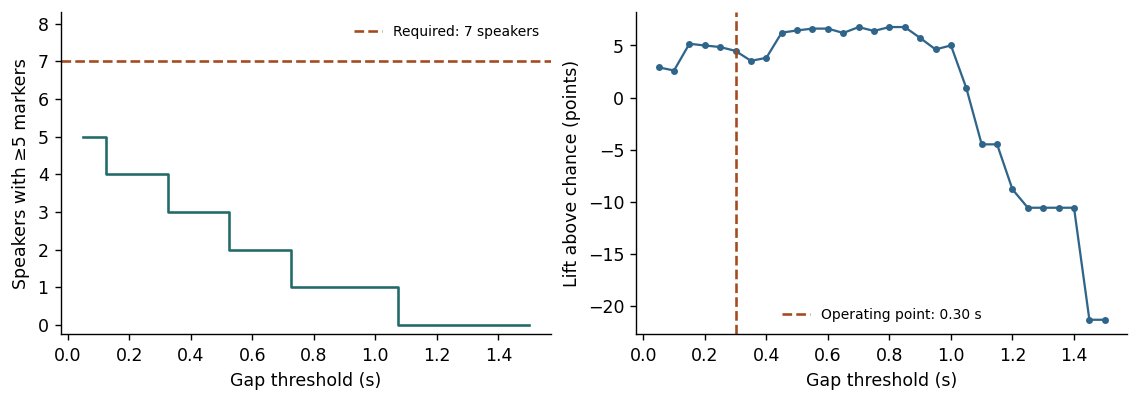

0 of 30 thresholds eligible. Using 0.30 s (historical fallback: insufficient calibration support).


In [31]:
# Plot the scores for all 30 pause lengths.
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(9, 3.1), layout="constrained")
ax1.step(curve.tau, curve.speakers_with_five, where="mid", color="#236b69")
ax1.axhline(7, ls="--", color="#a44920", label="Required: 7 speakers")
ax1.set(xlabel="Gap threshold (s)", ylabel="Speakers with ≥5 markers", ylim=(-0.25, 8.3))
ax1.legend(frameon=False, fontsize=8)
ax2.plot(curve.tau, 100 * curve.lift, color="#30658b", marker=".", linewidth=1.3)
ax2.axvline(tau, ls="--", color="#a44920", label=f"Operating point: {tau:.2f} s")
ax2.set(xlabel="Gap threshold (s)", ylabel="Lift above chance (points)")
ax2.legend(frameon=False, fontsize=8)
fig.savefig(tables / "threshold_curve.png", bbox_inches="tight")
draw(fig)
print(
    f"{int(curve.eligible.sum())} of {len(curve)} thresholds eligible. Using {tau:.2f} s ({lock['source']})."
)

<a id="section-3"></a>

## 3. Compare the two Whisper models

The graph shows validation WER as training progressed. Step 800 was chosen using the validation recordings. A separate set of recordings was used to apply the pause-threshold selection rule.

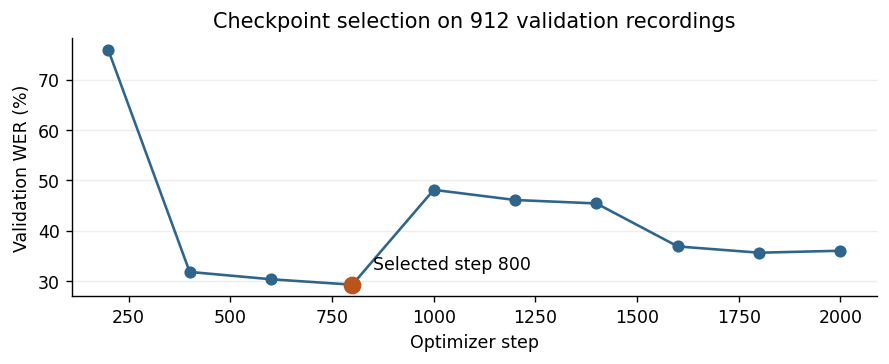

In [32]:
# Show how checkpoint selection depended on validation WER over training.
fig, ax = plt.subplots(figsize=(7, 2.8), layout="constrained")
ax.plot(training_history.step, 100 * training_history.wer, color="#30658b", marker="o")
ax.scatter(
    summary["selected_step"], 100 * summary["selection_wer"], s=85, color="#ba531c", zorder=4
)
ax.annotate(
    f"Selected step {summary['selected_step']}",
    (summary["selected_step"], 100 * summary["selection_wer"]),
    xytext=(12, 9),
    textcoords="offset points",
)
ax.set(
    xlabel="Optimizer step",
    ylabel="Validation WER (%)",
    title="Checkpoint selection on 912 validation recordings",
)
ax.grid(axis="y", alpha=0.22)
draw(fig)

<a id="transcribe"></a>

### Transcribe the recordings

Both models transcribe the same audio at 16 kHz. At each step, each model picks its most likely next token. The example shows both transcripts beside the reference text.

In [33]:
# Decode the held-out waveform with both recognizers and identical greedy settings.
base_dir = snapshot_download(
    "openai/whisper-tiny",
    revision=summary["recipe"]["base_revision"],
    allow_patterns=["*.json", "*.txt", "model.safetensors"],
)
processor = WhisperProcessor.from_pretrained(checkpoint)


def decode_block(frame):
    outputs = []
    for start in range(0, len(frame), ASR_BATCH):
        names = frame.audio_name.iloc[start : start + ASR_BATCH].tolist()
        inputs = processor.feature_extractor(
            [waveform(n) for n in names],
            sampling_rate=16000,
            return_attention_mask=True,
            return_tensors="pt",
        ).to(device)
        amp = (
            torch.autocast("cuda", dtype=torch.float16)
            if device.type == "cuda"
            else contextlib.nullcontext()
        )
        with torch.inference_mode(), amp:
            ids = asr.generate(**inputs)
        texts = processor.batch_decode(ids, skip_special_tokens=True)
        outputs.extend(dict(audio_name=n, text=t) for n, t in zip(names, texts))
    return outputs

Fetching 11 files:   0%|          | 0/11 [00:00<?, ?it/s]

generation_config.json: 0.00B [00:00, ?B/s]

added_tokens.json: 0.00B [00:00, ?B/s]

config.json: 0.00B [00:00, ?B/s]

model.safetensors:   0%|          | 0.00/151M [00:00<?, ?B/s]

normalizer.json: 0.00B [00:00, ?B/s]

... (2 outputs left out)

vocab.json: 0.00B [00:00, ?B/s]

preprocessor_config.json: 0.00B [00:00, ?B/s]

merges.txt: 0.00B [00:00, ?B/s]

tokenizer_config.json: 0.00B [00:00, ?B/s]

In [34]:
# Run both models on the selected recordings.
ev = cohort[
    [
        "sample_id",
        "audio_name",
        "recording",
        "speaker",
        "speech_status",
        "mic",
        "partition",
        "transcription",
    ]
].copy()
for system, directory in [
    ("asr", checkpoint),
    ("zero_shot", base_dir),
]:
    asr = WhisperForConditionalGeneration.from_pretrained(directory).eval().to(device)
    asr.generation_config = GenerationConfig.from_pretrained(checkpoint)
    raw = sharded(system, cohort, decode_block)
    ev[system] = [r["text"] for r in raw]
    del asr
    release_gpu()

asr:   0%|          | 0/57 [00:00<?, ?it/s]

`generation_config` default values have been modified to match model-specific defaults: {'suppress_tokens': [], 'begin_suppress_tokens': [220, 50257]}. If this is not desired, please set these values explicitly.
A custom logits processor of type <class 'transformers.generation.logits_process.SuppressTokensLogitsProcessor'> has been passed to `.generate()`, but it was also created in `.generate()`, given its parameterization. The custom <class 'transformers.generation.logits_process.SuppressTokensLogitsProcessor'> will take precedence. Please check the docstring of <class 'transformers.generation.logits_process.SuppressTokensLogitsProcessor'> to see related `.generate()` flags.
A custom logits processor of type <class 'transformers.generation.logits_process.SuppressTokensAtBeginLogitsProcessor'> has been passed to `.generate()`, but it was also created in `.generate()`, given its parameterization. The custom <class 'transformers.generation.logits_process.SuppressTokensAtBeginLogitsProce

asr | free RAM GiB 27.5 | free disk GiB 19.5 | device Tesla T4


zero_shot:   0%|          | 0/57 [00:00<?, ?it/s]

zero_shot | free RAM GiB 27.3 | free disk GiB 19.5 | device Tesla T4


In [35]:
# Save the transcripts and compare one example.
for col in ["transcription", "asr", "zero_shot"]:
    ev[col + "_normalized"] = ev[col].map(norm_del)
    ev[col + "_punct_to_space"] = ev[col].map(norm_space)
table("exact_asr_predictions", ev)
sample = ev[ev.transcription.str.split().str.len().between(4, 9)].iloc[0]
show(
    pd.DataFrame(
        {
            "Source": ["Reference", "Base Whisper", "Adapted Whisper"],
            "Text": [sample.transcription, sample.zero_shot, sample.asr],
        }
    )
)
print("Example recording:", sample.recording)

Source,Text
Reference,The quick brown fox jumps over the lazy dog
Base Whisper,"The quick bump, fuck, come over the lady dog."
Adapted Whisper,The quick-bound fog comes over the lighting off


Example recording: F01_1_0031


<a id="word-error-rate"></a>

### Read the word error rates

Word error rate (WER) counts replaced, missing, and extra words, then divides by the number of reference words. Lower is better. Each row uses all the reference words in that group. An empty transcript misses every reference word.

In [36]:
# Calculate corpus WER by summing edits and reference words within each speaker group.
def groups(frame):
    yield "all", frame
    for label, d in frame.groupby("speech_status"):
        yield label, d


def corpus_score(d, col, normalizer=norm_del):
    refs = d.transcription.map(normalizer).tolist()
    hyps = d[col].map(normalizer).tolist()
    assert all(refs)
    o = jiwer.process_words(refs, hyps)
    return dict(
        recordings=len(d),
        words=o.hits + o.substitutions + o.deletions,
        S=o.substitutions,
        D=o.deletions,
        I=o.insertions,
        WER=o.wer,
        CER=jiwer.cer(refs, hyps),
        MER=o.mer,
        empty_hypotheses=hyps.count(""),
    )

In [37]:
# Calculate word error rates for each group.
scores = [
    dict(system=col, population=key, normalizer=norm.__name__, **corpus_score(d, col, norm))
    for key, d in groups(ev)
    for norm in [norm_del, norm_space]
    for col in ["asr", "zero_shot"]
]
accuracy = table("asr_accuracy", scores)
table(
    "asr_by_speaker",
    [
        dict(system=col, speaker=sp, **corpus_score(d, col))
        for sp, d in ev.groupby("speaker")
        for col in ["asr", "zero_shot"]
    ],
)
wer_table = (
    accuracy[accuracy.normalizer.eq("norm_del")]
    .pivot(index="population", columns="system", values="WER")
    .mul(100)
)
wer_table = wer_table.rename(columns={"asr": "Adapted WER (%)", "zero_shot": "Base WER (%)"})
show(wer_table.rename_axis("Population").reset_index())

Population,Adapted WER (%),Base WER (%)
all,32.11,45.34
dysarthria,50.16,88.41
healthy,22.77,23.07


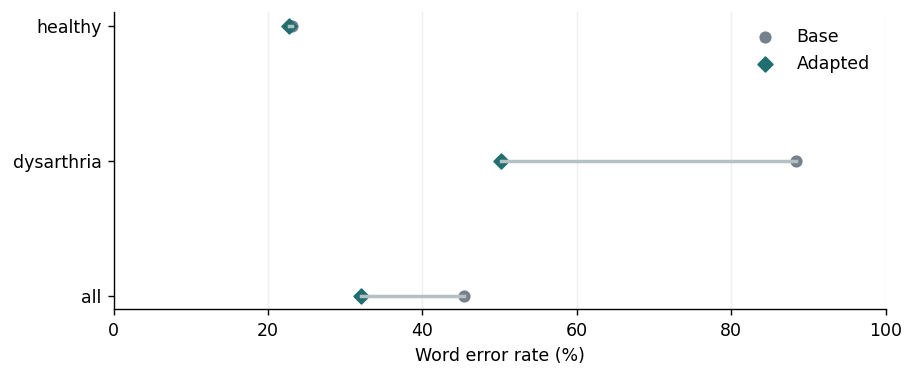

In [38]:
# Plot the difference between the two models.
fig, ax = plt.subplots(figsize=(7.2, 2.9), layout="constrained")
for y, (group, row) in enumerate(wer_table.iterrows()):
    ax.plot([row.iloc[0], row.iloc[1]], [y, y], color="#b5c0c5", lw=2)
    ax.scatter(row.iloc[1], y, color="#75818b", label="Base" if y == 0 else None)
    ax.scatter(row.iloc[0], y, color="#216e70", marker="D", label="Adapted" if y == 0 else None)
ax.set(
    yticks=range(len(wer_table)),
    yticklabels=wer_table.index,
    xlabel="Word error rate (%)",
    xlim=(0, max(100, wer_table.max().max() * 1.05)),
)
ax.legend(frameon=False)
ax.grid(axis="x", alpha=0.2)
draw(fig)

<a id="section-4"></a>

## 4. Compare word times in the two transcripts

The same timing model reads the audio twice, once with Whisper’s text and once with the reference text. The notebook compares a gap only when it can match the words on either side. A replaced word can still have a match. An extra or missing word can break the match.

The reference pass receives only the waveform and the written reference. Its timestamps are independent of Whisper’s hypothesis. The two passes share the acoustic model and segmenter, and the prompt can differ from what the speaker produced. The comparison uses a deterministic minimum-edit mapping, so its 817 shared dysarthric boundaries are a selected subset of the 1,023 timed hypothesis boundaries. Reference timing is an evaluation check. The editor only receives hypothesis-derived markers.

In [39]:
# Time the hypothesis and reference independently, then inspect a real sequence of words.
def dual_block(frame):
    return [
        dict(
            audio_name=r.audio_name,
            hyp=timed(r.asr, r.audio_name),
            ref=timed(r.transcription, r.audio_name),
        )
        for r in frame.itertuples()
    ]

In [40]:
# Measure word times for both transcripts.
aligner = load_aligner()
dual = sharded("dual_ctc", ev, dual_block)
del aligner
release_gpu()

Some weights of Wav2Vec2ForCTC were not initialized from the model checkpoint at /root/.cache/huggingface/hub/models--facebook--wav2vec2-base-960h/snapshots/22aad52d435eb6dbaf354bdad9b0da84ce7d6156 and are newly initialized: ['wav2vec2.masked_spec_embed']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


dual_ctc:   0%|          | 0/57 [00:00<?, ?it/s]

dual_ctc | free RAM GiB 28.0 | free disk GiB 19.5 | device Tesla T4


In [41]:
# Match the time and error information for each recording.
def describe_record(row, timing):
    hyp, ref = norm_del(row.asr).split(), norm_del(row.transcription).split()
    tok, dele, pairs = find_asr_errors(ref, hyp, with_pairs=True)
    index = dict(pairs)  # hypothesis index -> reference index, including substitutions
    hs, rs = timing["hyp"], timing["ref"]
    htimes, rtimes = hs["times"], rs["times"]
    bounds = []
    for b in range(1, len(hyp)):
        left, right = index.get(b - 1), index.get(b)
        mapped = left is not None and right is not None and right == left + 1
        bounds.append(
            dict(
                b=b,
                ref_b=right if mapped else None,
                hyp_gap=htimes[b - 1]["pause_after"] if htimes else None,
                ref_gap=rtimes[right - 1]["pause_after"] if mapped and rtimes else None,
                near=sorted(errors_near(b, tok, dele, 2)),
            )
        )
    return dict(
        audio_name=row.audio_name,
        recording=row.recording,
        speaker=row.speaker,
        status=row.speech_status,
        n_errors=len(tok) + len(dele),
        n_ref=len(ref),
        hyp_status=hs["status"],
        ref_status=rs["status"],
        n_hyp=len(hyp),
        n_ref_internal=max(0, len(ref) - 1),
        bounds=bounds,
    )


records = [describe_record(row, timing) for row, timing in zip(ev.itertuples(), dual)]
assert len(records) == len(ev)

In [42]:
# Show an example where both transcripts have word times.
example_index = next(
    (i for i, item in enumerate(dual) if item["hyp"]["times"] and item["ref"]["times"]), None
)
if example_index is None:
    print("No recording has two usable timing passes in this cohort.")
else:
    timing_example = dual[example_index]
    print("Recording:", timing_example["audio_name"])
    timing_preview = pd.DataFrame(timing_example["hyp"]["times"]).head(6)
    show(
        timing_preview[["word", "start", "end", "pause_after"]].rename(
            columns={
                "word": "Whisper word",
                "start": "Start (s)",
                "end": "End (s)",
                "pause_after": "Following gap (s)",
            }
        )
    )

Recording: F01_1_headMic_0031.wav


Whisper word,Start (s),End (s),Following gap (s)
THE,0.25,0.68,0.00
QUICKBOUND,0.68,1.63,0.00
FOG,1.63,1.93,0.00
COMES,1.93,2.62,0.00
OVER,2.62,3.12,0.00
THE,3.12,3.32,0.00


<a id="shared-gaps"></a>

### Count gaps that can be compared

A shared gap needs a time from both passes and a matching pair of neighboring words. The table counts how many gaps meet those rules.

In [43]:
# Keep only adjacent, corresponding word pairs for a direct comparison of the two clocks.
flat = []
flow = []
for r in records:
    bounds = r["bounds"]
    flow.append(
        {
            **{k: v for k, v in r.items() if k != "bounds"},
            "hyp_internal": len(bounds),
            "text_mapped": sum(b["ref_b"] is not None for b in bounds),
            "jointly_timed": sum(
                b["hyp_gap"] is not None and b["ref_gap"] is not None for b in bounds
            ),
            "hyp_markers": sum(b["hyp_gap"] is not None and b["hyp_gap"] >= tau for b in bounds),
        }
    )
    for b in bounds:
        flat.append(
            {
                **b,
                "recording": r["recording"],
                "speaker": r["speaker"],
                "status": r["status"],
                "near": json.dumps(b["near"]),
            }
        )
table(
    "boundary_map",
    flat,
    ["recording", "speaker", "status", "b", "ref_b", "hyp_gap", "ref_gap", "near"],
)
table("timing_flow", flow)
write_json(out / "timed_recordings.json", records)

In [44]:
# Check the rules for matching gaps.
def boundary_pool(r, source):
    if source == "hyp_native":
        return [(b, "hyp_gap") for b in r["bounds"] if b["hyp_gap"] is not None]
    field = "hyp_gap" if source == "hyp_matched" else "ref_gap"
    return [
        (b, field) for b in r["bounds"] if b["hyp_gap"] is not None and b["ref_gap"] is not None
    ]


def check_alignment_logic():
    tokens, deleted, pairs = find_asr_errors("A B C".split(), "A X C".split(), with_pairs=True)
    assert tokens == {1} and not deleted and dict(pairs) == {0: 0, 1: 1, 2: 2}
    assert find_asr_errors(["A", "X", "C"], ["A", "C"], with_pairs=True)[1] == {(1, 1)}
    assert find_asr_errors(["A", "C"], ["A", "X", "C"], with_pairs=True)[0] == {1}
    assert len(find_asr_errors(["A", "B"], [], with_pairs=True)[1]) == 2


check_alignment_logic()

In [45]:
# Show how many gaps can be compared.
timing_summary = (
    pd.DataFrame(flow)
    .groupby("status")[["hyp_internal", "text_mapped", "jointly_timed", "hyp_markers"]]
    .sum()
)
show(
    timing_summary.rename_axis("Speaker group")
    .reset_index()
    .rename(
        columns={
            "hyp_internal": "Whisper boundaries",
            "text_mapped": "Mapped in text",
            "jointly_timed": "Timed in both",
            "hyp_markers": "Whisper markers",
        }
    )
)

Speaker group,Whisper boundaries,Mapped in text,Timed in both,Whisper markers
dysarthria,1030,825,817,82
healthy,2095,1744,1729,1


<a id="section-5"></a>

## 5. Add pause markers to the text

A gap earns a marker if it is at least as long as the chosen pause length. For example, `[0.4s_pause]` appears after the word before a pause. The label rounds the time to one decimal place. The decision uses the gap rounded to milliseconds before formatting the label.

In [46]:
# Insert a marker between words only when their measured gap reaches the threshold.
def marker_text(words, positions, durations):
    tags = {b: f"[{duration:.1f}s_pause]" for b, duration in zip(positions, durations)}
    tokens = []
    for i, word in enumerate(words, 1):
        tokens.append(word)
        if i in tags:
            tokens.append(tags[i])
    return " ".join(tokens)

In [47]:
# Find a recording with a marked pause.
for row, alignment in zip(ev.itertuples(), dual):
    times = alignment["hyp"]["times"]
    marked = [i for i, time_word in enumerate(times[:-1], 1) if time_word["pause_after"] >= tau]
    if marked:
        durations = [times[i - 1]["pause_after"] for i in marked]
        print("Recording:", row.recording)
        print("ASR:", row.asr)
        print("With markers:", marker_text(norm_del(row.asr).split(), marked, durations))
        break
else:
    print("No eligible internal pause in this cohort.")

Recording: F03_1_0095
ASR:  When he speaks, his voice is just a bit cracked and that covers Emma Tuffell
With markers: WHEN HE SPEAKS HIS VOICE IS JUST A BIT CRACKED [0.4s_pause] AND THAT COVERS EMMA TUFFELL


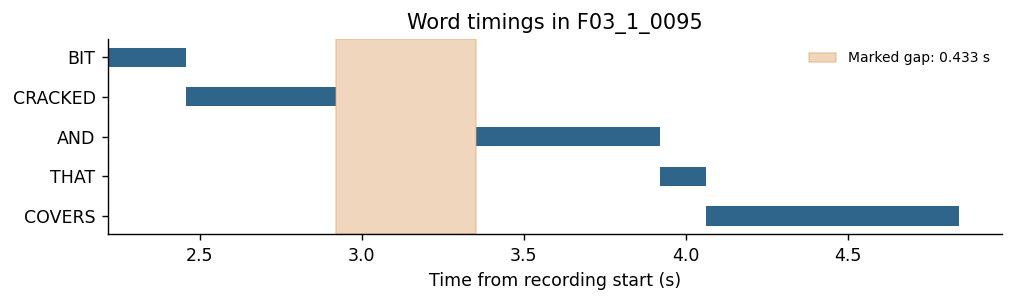

In [48]:
# Plot the words on either side of that pause.
if any(
    item["hyp"]["times"]
    and any(
        w["pause_after"] is not None and w["pause_after"] >= tau for w in item["hyp"]["times"]
    )
    for item in dual
):
    # Focus on at most five words around the first marked pause shown above.
    boundary = marked[0]
    nearby = times[max(0, boundary - 2) : boundary + 3]
    fig, axis = plt.subplots(figsize=(8, 2.3), layout="constrained")
    for level, word in enumerate(nearby):
        axis.barh(
            level, word["end"] - word["start"], left=word["start"], height=0.48, color="#30658b"
        )
    left = times[boundary - 1]["end"]
    right = times[boundary]["start"]
    axis.axvspan(
        left, right, color="#e0a66f", alpha=0.45, label=f"Marked gap: {durations[0]:.3f} s"
    )
    axis.set(
        yticks=range(len(nearby)),
        yticklabels=[w["word"] for w in nearby],
        xlabel="Time from recording start (s)",
        title=f"Word timings in {row.recording}",
    )
    axis.invert_yaxis()
    axis.legend(frameon=False, fontsize=8, loc="upper right")
    draw(fig)

<a id="section-6"></a>

## 6. Test whether pauses are near errors

**Reliability** asks “What share of markers are near an error?” **Coverage** asks “What share of errors have a marker nearby?” For a fair comparison, each recording gets the same number of random markers as real ones. **Lift** is the real score minus the expected random score, in percentage points.

In [49]:
# Compute reliability and distinct error coverage for one recording at a time.
def ratio(a, b):
    return a / b if b else np.nan


def rec_stats(r, source, rng):
    pool = boundary_pool(r, source)
    errors_by_boundary = [set(map(tuple, b["near"])) for b, _ in pool]
    marker_indices = [i for i, (b, field) in enumerate(pool) if b[field] >= tau]
    n, k = len(pool), len(marker_indices)
    total_errors = r["n_errors"]
    covered = set().union(*(errors_by_boundary[i] for i in marker_indices))
    near_marker_count = sum(bool(errors_by_boundary[i]) for i in marker_indices)
    expected_near_markers = k * sum(bool(x) for x in errors_by_boundary) / n if n else 0.0
    expected_covered_errors = 0.0
    random_counts = np.zeros((N_PERM, 2), dtype=int)
    # For each error, compute the chance that at least one random marker reaches it.
    # This counts a covered error once even when several marker windows overlap.
    if k:
        denominator = math.comb(n, k)
        boundaries_per_error = Counter(e for group in errors_by_boundary for e in group)
        expected_covered_errors = sum(
            1 - math.comb(n - f, k) / denominator for f in boundaries_per_error.values()
        )
        hits = np.array([bool(a) for a in errors_by_boundary], int)
        # Each row is a uniformly chosen k-subset. OR coverage de-duplicates edits.
        chosen = np.argpartition(rng.random((N_PERM, n)), k - 1, axis=1)[:, :k]
        random_counts[:, 0] = hits[chosen].sum(axis=1)
        for e in boundaries_per_error:
            reaches = np.array([e in a for a in errors_by_boundary])
            random_counts[:, 1] += reaches[chosen].any(axis=1)
    return [
        k,
        near_marker_count,
        expected_near_markers,
        total_errors,
        len(covered),
        expected_covered_errors,
        n,
        total_errors if n else 0,
    ], random_counts

Set up the calculations for scores and uncertainty.

In [50]:
def bootstrap_indices(speakers, rng):
    # Same number of recordings per observed speaker, conditional on this speaker set.
    groups_ix = [np.flatnonzero(speakers == s) for s in sorted(set(speakers))]
    for _ in range(N_BOOT):
        yield np.concatenate([rng.choice(ix, size=len(ix), replace=True) for ix in groups_ix])


def position_metrics(v):
    k, h, eh, e, c, ec, opps, with_pool_errors = v
    return dict(
        reliability=ratio(h, k),
        chance=ratio(eh, k),
        lift=ratio(h - eh, k),
        coverage=ratio(c, e),
        random_coverage=ratio(ec, e),
        coverage_gain=ratio(c - ec, e),
        coverage_among_pool_recordings=ratio(c, with_pool_errors),
    )


def interval(values):
    finite = np.asarray(values, dtype=float)
    finite = finite[np.isfinite(finite)]
    return tuple(np.quantile(finite, [0.025, 0.975])) if len(finite) else (np.nan, np.nan)


# Check the unit of analysis on a real marked recording.

Show which errors the markers reach in one recording.

In [51]:
example = next(
    (
        r
        for r in records
        if any(b["hyp_gap"] is not None and b["hyp_gap"] >= tau for b in r["bounds"])
    ),
    None,
)
if example is not None:
    counts, _ = rec_stats(example, "hyp_native", np.random.default_rng(SEED))
    print(
        f"{example['recording']}: {counts[0]} markers, {counts[1]} near an error; {counts[4]} distinct errors covered out of {counts[3]}."
    )
else:
    print("No marked recording available for the worked example.")

F03_1_0095: 1 markers, 1 near an error; 1 distinct errors covered out of 4.


<a id="random-comparison"></a>

### Compare pauses with random markers

The notebook tries random positions many times to see how often they score as well as the real pauses. To estimate uncertainty, it also repeats the calculation with new samples of whole recordings from each speaker.

In [52]:
# Aggregate by timing source, keeping the same within-recording opportunities in both matched rows.
sources = ["hyp_native", "hyp_matched", "ref_matched"]
loc_rows, paired_rows, speaker_rows, agreement = [], [], [], []
for population, subset in [
    ("dysarthria", [r for r in records if r["status"] == "dysarthria"]),
    ("all", records),
]:
    if not subset:
        continue
    speakers = np.array([r["speaker"] for r in subset])
    matrices, reps = {}, {}
    for source in sources:
        # Each source has the same seed and its own within-recording marker counts.
        # Bootstrap draws below use the same recording indices for the paired interval.
        rng = np.random.default_rng(SEED)
        stats, null = [], np.zeros((N_PERM, 2), int)
        for r in subset:
            v, sim = rec_stats(r, source, rng)
            stats.append(v)
            null += sim
        mat = np.asarray(stats, float)
        matrices[source] = mat
        totals = mat.sum(axis=0)
        row = dict(
            population=population,
            source=source,
            recordings=len(subset),
            recordings_with_pool=int((mat[:, 6] > 0).sum()),
            recordings_marked=int((mat[:, 0] > 0).sum()),
            boundaries=int(totals[6]),
            markers=int(totals[0]),
            near_markers=int(totals[1]),
            errors=int(totals[3]),
            covered_errors=int(totals[4]),
            **position_metrics(totals)
        )
        row.update(p_reliability=np.nan, p_coverage=np.nan)
        if totals[0] and totals[3]:
            row["p_reliability"] = (1 + (null[:, 0] >= totals[1]).sum()) / (N_PERM + 1)
            row["p_coverage"] = (1 + (null[:, 1] >= totals[4]).sum()) / (N_PERM + 1)
        reps[source] = pd.DataFrame(
            [
                position_metrics(mat[ix].sum(axis=0))
                for ix in bootstrap_indices(speakers, np.random.default_rng(SEED))
            ]
        )
        for metric in ["reliability", "lift", "coverage", "coverage_gain"]:
            row[metric + "_lo"], row[metric + "_hi"] = interval(reps[source][metric])
        loc_rows.append(row)
        if population == "dysarthria":
            for speaker in sorted(set(speakers)):
                v = mat[speakers == speaker].sum(axis=0)
                speaker_rows.append(
                    dict(
                        speaker=speaker,
                        source=source,
                        markers=int(v[0]),
                        errors=int(v[3]),
                        covered_errors=int(v[4]),
                        **position_metrics(v)
                    )
                )
    for metric in ["lift", "reliability", "coverage", "coverage_gain"]:
        diff = (
            position_metrics(matrices["ref_matched"].sum(axis=0))[metric]
            - position_metrics(matrices["hyp_matched"].sum(axis=0))[metric]
        )
        lo, hi = interval(reps["ref_matched"][metric] - reps["hyp_matched"][metric])
        paired_rows.append(
            dict(
                population=population,
                metric=metric,
                reference_minus_hypothesis=diff,
                lo=lo,
                hi=hi,
            )
        )
    paired = [
        (b["hyp_gap"] >= tau, b["ref_gap"] >= tau)
        for r in subset
        for b, _ in boundary_pool(r, "hyp_matched")
    ]
    counts = Counter(paired)
    agreement.append(
        dict(
            population=population,
            common_boundaries=len(paired),
            both=counts[True, True],
            only_hyp=counts[True, False],
            only_ref=counts[False, True],
            neither=counts[False, False],
            positive_jaccard=ratio(counts[True, True], len(paired) - counts[False, False]),
        )
    )

Save the comparisons and show the results for speakers with dysarthria.

In [53]:
table("localization", loc_rows)
table("localization_by_speaker", speaker_rows)
table("timing_paired_differences", paired_rows)
table("timing_marker_agreement", agreement)
source_names = {
    "hyp_native": "Whisper · all timed",
    "hyp_matched": "Whisper · shared",
    "ref_matched": "Reference · shared",
}
pos = pd.DataFrame(loc_rows).query("population == 'dysarthria'").set_index("source")
near_table = pd.DataFrame(
    {
        "Timing": pos.index.map(source_names),
        "Markers": pos.markers,
        "Near error (%)": 100 * pos.reliability,
        "Chance (%)": 100 * pos.chance,
        "Lift (points)": 100 * pos.lift,
        "Permutation p": pos.p_reliability.round(3).astype(str),
    }
)
show(near_table.reset_index(drop=True))

Timing,Markers,Near error (%),Chance (%),Lift (points),Permutation p
Whisper · all timed,82,85.37,84.95,0.41,0.529
Whisper · shared,59,79.66,78.25,1.41,0.425
Reference · shared,55,80.00,77.43,2.57,0.341


<a id="gain-plot"></a>

### Read the graph

Each dot shows how much the pause markers gained or lost compared with random placement. The horizontal line is a 95% interval for that difference. If it crosses zero, both a gain and a loss are consistent with the estimate.

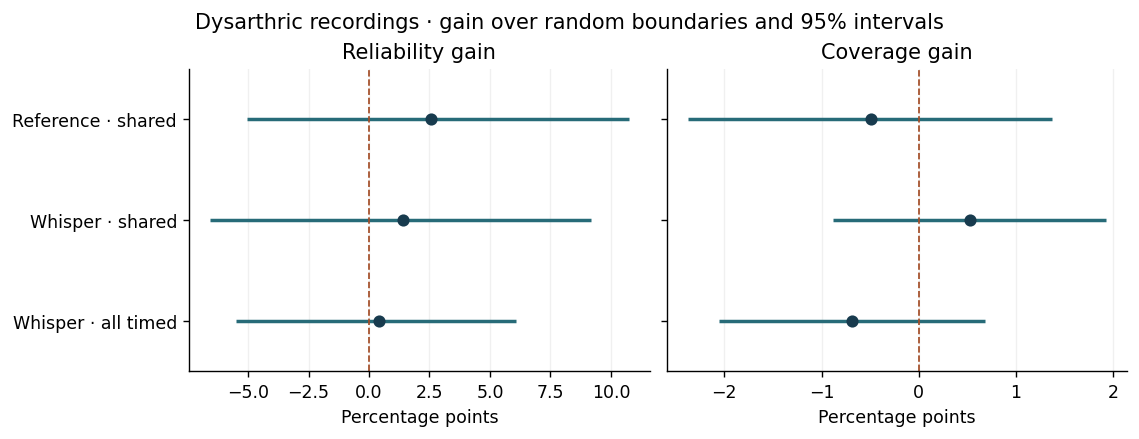

In [54]:
# Compare the gain with zero and show the bootstrap uncertainty for each timing source.
# Zero on this scale means the observed marker positions performed like random positions.
fig, axes = plt.subplots(1, 2, figsize=(9, 3.4), layout="constrained", sharey=True)
for ax, metric, title in zip(
    axes, ["lift", "coverage_gain"], ["Reliability gain", "Coverage gain"]
):
    for y, (source, row) in enumerate(pos.iterrows()):
        value, lo, hi = 100 * row[[metric, metric + "_lo", metric + "_hi"]].to_numpy(dtype=float)
        if np.isfinite([value, lo, hi]).all():
            ax.hlines(y, lo, hi, color="#276b78", lw=2)
            ax.scatter(value, y, color="#183b4e", zorder=3)
    ax.axvline(0, color="#a34d27", ls="--", lw=1)
    ax.set(
        title=title,
        xlabel="Percentage points",
        yticks=range(len(pos)),
        yticklabels=pos.index.map(source_names),
        ylim=(-0.5, len(pos) - 0.5),
    )
    ax.grid(axis="x", alpha=0.18)
fig.suptitle("Dysarthric recordings · gain over random boundaries and 95% intervals")
fig.savefig(tables / "localization_vs_random.png", bbox_inches="tight")
draw(fig)

In [55]:
# Read the coverage and timing agreement for this run.
base = pos.loc["hyp_native"]
print(
    f"{int(base.covered_errors)} of {int(base.errors)} word errors were covered ({base.coverage:.2%}). Expected random coverage: {base.random_coverage:.2%}."
)
agreement_view = (
    pd.read_csv(tables / "timing_marker_agreement.csv").query("population=='dysarthria'").iloc[0]
)
print(
    f"On {int(agreement_view.common_boundaries)} shared boundaries, both timing sources marked {int(agreement_view.both)}; Whisper alone marked {int(agreement_view.only_hyp)} and reference timing alone marked {int(agreement_view.only_ref)}."
)

144 of 775 word errors were covered (18.58%). Expected random coverage: 19.26%.
On 817 shared boundaries, both timing sources marked 41; Whisper alone marked 18 and reference timing alone marked 14.


<a id="recording-errors"></a>

### Count recordings with errors

For recordings with at least two reference words, the table shows how often a recording has any word error. Here each recording counts once, even if it has several errors or markers.

In [56]:
# For multiword references, compare error prevalence in flagged and unflagged utterances.
# Paper's secondary utterance-level association, restricted to multiword references.
association = []
for r in records:
    if r["n_ref"] < 2:
        continue
    valid = r["hyp_status"] in ("aligned", "no_internal_boundary")
    gaps = [b["hyp_gap"] for b in r["bounds"] if b["hyp_gap"] is not None]
    gap = max(gaps, default=0.0) if valid else np.nan
    association.append(
        dict(
            recording=r["recording"],
            status=r["status"],
            speaker=r["speaker"],
            max_gap=gap,
            flagged=valid and gap >= tau,
            errors=r["n_errors"],
            words=r["n_ref"],
        )
    )
utt = table(
    "utterance_association_records",
    association,
    ["recording", "status", "speaker", "max_gap", "flagged", "errors", "words"],
)

In [57]:
# Compare recordings with and without a marked pause.
utt_rows = []
for label, sub in [("all", utt), ("dysarthria", utt[utt.status.eq("dysarthria")])]:
    d = sub.dropna(subset=["max_gap"])

    def auc(g):
        y = g.errors.gt(0)
        return roc_auc_score(y, g.max_gap) if y.nunique() == 2 else np.nan

    within = [
        auc(g) for _, g in d.groupby("speaker") if len(g) >= 20 and g.errors.gt(0).nunique() == 2
    ]
    for flag in [True, False]:
        g = d[d.flagged.eq(flag)]
        utt_rows.append(
            dict(
                population=label,
                flagged=flag,
                n=len(g),
                excluded_ctc=len(sub) - len(d),
                wer=ratio(g.errors.sum(), g.words.sum()),
                p_any_error=g.errors.gt(0).mean(),
                pooled_auc=auc(d),
                within_speaker_mean_auc=np.mean(within) if within else np.nan,
            )
        )

In [58]:
# Count which recordings reached each stage.
table("utterance_association", utt_rows)
cohort_flow = []
for label, d in groups(ev):
    ids = set(d.recording)
    rf = [r for r in flow if r["recording"] in ids]
    cohort_flow.append(
        dict(
            population=label,
            recordings=len(d),
            speakers=d.speaker.nunique(),
            multiword_reference=int(
                d.transcription.map(lambda s: len(norm_del(s).split()) >= 2).sum()
            ),
            hypothesis_internal_boundaries=sum(r["hyp_internal"] for r in rf),
            jointly_timed_boundaries=sum(r["jointly_timed"] for r in rf),
            marked_files=sum(r["hyp_markers"] > 0 for r in rf),
            markers=sum(r["hyp_markers"] for r in rf),
            n_errors=sum(r["n_errors"] for r in rf),
            hypothesis_ctc=dict(Counter(r["hyp_status"] for r in rf)),
            reference_ctc=dict(Counter(r["ref_status"] for r in rf)),
        )
    )
write_json(out / "evaluation_flow.json", cohort_flow)

In [59]:
# Show the error rates and save the audio analysis.
risk = pd.DataFrame(utt_rows).query("population=='dysarthria'").copy()
risk["Any error (%)"] = 100 * risk.p_any_error
show(
    risk[["flagged", "n", "Any error (%)", "excluded_ctc"]].rename(
        columns={
            "flagged": "Has pause marker",
            "n": "Recordings",
            "excluded_ctc": "Unavailable timings in cohort",
        }
    )
)
write_json(out / "progress.json", dict(stage="acoustic_complete", mode=mode, completed=now(),
                                     scope=eval_part, n_evaluation=len(ev), llm_backend=None))
export_zip("_acoustic")

Has pause marker,Recordings,Any error (%),Unavailable timings in cohort
True,47,95.74,1
False,100,73.00,1


Saved /kaggle/working/iciss_fresh_full_20261112T053554Z_7b6c322ff5_acoustic.zip


PosixPath('/kaggle/working/iciss_fresh_full_20261112T053554Z_7b6c322ff5_acoustic.zip')

<a id="section-7"></a>

## 7. Try editing the words near a pause

The editor sees up to four words on each side of a pause. Overlapping groups of words are joined. The notebook runs the editor with visible pauses, with the same pauses hidden, and with words chosen around random gaps. The random version must cover different words using the same number and lengths of text regions.

Visible and hidden conditions use identical words and guard limits. The hidden prompt also removes marker-specific instructions. The contrast estimates the combined effect of showing markers and explaining their use. Randomized windows preserve marker count, displayed durations, calls and region lengths after clipping and merging. They can overlap the real windows. The matched subset requires a different overall editable-word mask.

In [60]:
# Keep the original correction examples, prompt wording and edit-distance guard.
PROMPT_EXAMPLES = {
    "original": "QUISH -> QUICK\nWASH WASH -> WASH\nSNOWISH -> SNOW",
    "neutral": "KITCHUN -> KITCHEN\nBLUE BLUE -> BLUE\nSPOONFULISH -> SPOONFUL",
}

SYSTEM_PROMPT = """
You are a conservative ASR transcription error-correction system for
dysarthric speech.

The input is a SHORT LOCAL ASR segment containing pause markers such as
[0.7s_pause].

Pause markers represent acoustic silence and are only POSSIBLE cues for
an ASR recognition error. A pause does NOT mean an error definitely exists.

Your goal is to recover obvious ASR recognition errors, NOT to rewrite,
polish, or improve the sentence.

DEFAULT ACTION:
KEEP THE INPUT UNCHANGED.

Make a correction only when there is strong evidence that a specific
token is an ASR recognition error.

HIGH-CONFIDENCE corrections include:

- an obviously malformed or corrupted word,
- an obvious phonetic near-miss,
- an accidentally repeated word,
- an obviously missing word,
- an obviously spurious extra word.

Examples of the type of correction that may be appropriate:

{examples}

STRICT RULES:

1. Prefer NO CHANGE whenever uncertain.

2. A pause marker alone is NOT evidence that a word is wrong.

3. Do NOT modify a correctly formed, contextually plausible word unless
   there is strong evidence that the word itself is an ASR recognition
   error.

4. Do NOT replace one plausible English word with another plausible
   English word based only on semantic or grammatical preference.

5. Do NOT paraphrase or use synonyms.

6. Do NOT perform general grammar correction.

7. Do NOT change tense, number, agreement, contractions, or word form
   merely to make the sentence grammatical.

8. Do NOT insert or delete function words such as:
   a, an, the, to, of, my, his, her, in, on, than, and
   merely to improve grammar or fluency.

   Change a function word only when there is strong local evidence
   that the function word itself was inserted, omitted, or
   misrecognized by ASR.

9. Do NOT change the spelling or form of a valid word unless there is
   strong evidence that the original token itself is an ASR
   recognition error.

10. Do NOT change a word because another possibly erroneous ASR word
    makes the phrase sound grammatically strange. The other word may
    itself be the recognition error.

11. Make the smallest possible correction.

12. Focus corrections on words close to the pause marker.

13. Preserve pause markers exactly as written when they appear.

14. If there is no obvious high-confidence ASR error, return the input
    unchanged.

Before every change, ask:

"Is the original token clearly more likely to be an ASR recognition
error than a valid spoken word?"

If the answer is not clearly YES, do not change it.

Return ONLY the resulting segment.
Do not provide explanations, labels, JSON, markdown, or alternatives.
""".replace(
    "{examples}", PROMPT_EXAMPLES[C.PROMPT_EXAMPLES]
)

Find the words around each pause marker.

In [61]:
PAUSE_RE = re.compile(r"^\[\d+(?:\.\d+)?s_pause\]$", re.IGNORECASE)


def is_pause(token):
    return bool(PAUSE_RE.fullmatch(token))


def remove_pause_markers(text):
    return " ".join(t for t in str(text).split() if not is_pause(t))


def normalize_words(text):
    return re.sub(r"[^A-Z0-9'\s]", "", str(text).upper()).split()


def extract_pause_regions(text, k):
    tokens = str(text).split()
    n = len(tokens)
    selected = [False] * n
    for p in [i for i, t in enumerate(tokens) if is_pause(t)]:
        selected[p] = True
        for step in (-1, 1):
            seen, i = 0, p + step
            while 0 <= i < n and seen < k:
                selected[i] = True
                if not is_pause(tokens[i]):
                    seen += 1
                i += step
    regions, i = [], 0
    while i < n:
        if not selected[i]:
            i += 1
            continue
        start = i
        while i < n and selected[i]:
            i += 1
        regions.append({"start": start, "end": i - 1, "input_region": " ".join(tokens[start:i])})
    return regions

Check how much each proposed edit changes the text.

In [62]:
def word_edit_distance(a, b):
    a, b = normalize_words(remove_pause_markers(a)), normalize_words(remove_pause_markers(b))
    prev = list(range(len(b) + 1))
    for i, wa in enumerate(a, 1):
        cur = [i]
        for j, wb in enumerate(b, 1):
            cur.append(min(prev[j - 1] + (wa != wb), prev[j] + 1, cur[j - 1] + 1))
        prev = cur
    return prev[-1]


def clean_llm_output(text):
    if text is None:
        return None
    text = re.sub(r"^```(?:text)?", "", str(text).strip(), flags=re.IGNORECASE)
    text = re.sub(r"```$", "", text).strip()
    text = re.sub(r"^(corrected|output|corrected segment)\s*:\s*", "", text, flags=re.IGNORECASE)
    return text.strip("\"' ")


def validate_llm_output(original, candidate):
    if candidate is None:
        return original, "llm_failure"
    candidate = clean_llm_output(candidate)
    if not candidate:
        return original, "empty_output"
    dist = word_edit_distance(original, candidate)
    if (
        dist > C.MAX_ABS_EDITS
        or dist / max(len(normalize_words(remove_pause_markers(original))), 1) > C.MAX_EDIT_RATIO
    ):
        return original, "excessive_rewrite"
    return candidate, "accepted"

Prepare the instructions for the editor when pause markers are hidden.

In [63]:
# Keep all non-marker-related correction rules and examples in the hidden arm.
HIDDEN_PROMPT = SYSTEM_PROMPT
for fragment in [
    "The input is a SHORT LOCAL ASR segment containing pause markers such as\n[0.7s_pause].",
    "Pause markers represent acoustic silence and are only POSSIBLE cues for\nan ASR recognition error. A pause does NOT mean an error definitely exists.",
    "2. A pause marker alone is NOT evidence that a word is wrong.",
    "12. Focus corrections on words close to the pause marker.",
    "13. Preserve pause markers exactly as written when they appear.",
]:
    assert fragment in HIDDEN_PROMPT
    HIDDEN_PROMPT = HIDDEN_PROMPT.replace(
        fragment,
        "The input is a short local ASR segment." if fragment.startswith("The input") else "",
    )
assert "pause marker" not in HIDDEN_PROMPT.lower()
write_json(
    out / "llm_prompts.json",
    dict(
        visible=SYSTEM_PROMPT,
        hidden=HIDDEN_PROMPT,
        model=C.LLM_MODEL,
        temperature=0,
        backend=("echo" if SMOKE else "Groq") if RUN_CORRECTION else None,
    ),
)
show(
    pd.DataFrame(
        [
            {
                "Editor": C.LLM_MODEL,
                "Words per side": C.LLM_K,
                "Maximum edits per region": C.MAX_ABS_EDITS,
                "Maximum edited fraction": C.MAX_EDIT_RATIO,
                "Temperature": 0,
            }
        ]
    )
)

Editor,Words per side,Maximum edits per region,Maximum edited fraction,Temperature
openai/gpt-oss-120b,4,2,0.40,0


<a id="edit-windows"></a>

### Choose which words the editor sees

Moving a marker can still give the editor the same words. The table counts how often it was possible to give the editor different words while keeping the amount of editable text the same.

In [64]:
# Construct real, hidden and random windows. Check the editing budget after merging.
def spans_for(n, positions):
    spans = []
    for b in positions:
        start, end = max(0, b - C.LLM_K), min(n, b + C.LLM_K)
        if spans and start <= spans[-1][1]:
            spans[-1] = (spans[-1][0], max(spans[-1][1], end))
        else:
            spans.append((start, end))
    return spans


def budget(spans):
    return sorted(end - start for start, end in spans)


def random_positions(n, real, recording):
    k = len(real)
    true_spans = spans_for(n, real)
    target = budget(true_spans)
    seed = int.from_bytes(hashlib.sha256(f"{SEED}|{recording}".encode()).digest()[:8], "big")
    rng = random.Random(seed)

    def feasible(pos):
        spans = spans_for(n, pos)
        return spans != true_spans and budget(spans) == target

    count = math.comb(n - 1, k)
    if count <= C.RANDOM_SEARCH_LIMIT:
        chosen = None
        matches = 0
        for pos in itertools.combinations(range(1, n), k):
            if feasible(pos):
                matches += 1
                if rng.randrange(matches) == 0:
                    chosen = list(pos)
        return chosen, "matched" if chosen is not None else "no_distinct_matched_mask"
    for _ in range(C.RANDOM_SEARCH_LIMIT):
        pos = sorted(rng.sample(range(1, n), k))
        if feasible(pos):
            return pos, "matched"
    return None, "search_exhausted"

Build the editor’s input for one condition.

In [65]:
def condition_plan(words, positions, durations, arm):
    formatted = marker_text(words, positions, durations)
    regions = extract_pause_regions(formatted, C.LLM_K)
    spans = spans_for(len(words), positions)
    assert len(regions) == len(spans)
    jobs = []
    for reg, (a, b) in zip(regions, spans):
        text = reg["input_region"]
        assert remove_pause_markers(text).split() == words[a:b]
        jobs.append(
            dict(
                start=a,
                end=b,
                input_region=remove_pause_markers(text) if arm == "hidden" else text,
            )
        )
    return dict(
        positions=positions,
        durations=durations,
        spans=spans,
        jobs=jobs,
        calls=len(spans),
        editable_words=sum(b - a for a, b in spans),
    )

Choose the edit locations for each recording.

In [66]:
arms = ["visible", "hidden", "random"]
plans = {}
budget_rows = []
for row, timing in zip(ev.itertuples(), dual):
    words = norm_del(row.asr).split()
    times = timing["hyp"]["times"]
    if times:
        assert [t["word"] for t in times] == words
    marks = [i for i, t in enumerate(times[:-1], 1) if t["pause_after"] >= tau]
    durations = [times[i - 1]["pause_after"] for i in marks]
    p = dict(
        recording=row.recording,
        audio_name=row.audio_name,
        marked=bool(marks),
        arms={},
        status="unflagged",
    )
    if marks:
        p["arms"]["visible"] = condition_plan(words, marks, durations, "visible")
        p["arms"]["hidden"] = condition_plan(words, marks, durations, "hidden")
        pos, p["status"] = random_positions(len(words), marks, row.recording)
        if pos is not None:
            p["arms"]["random"] = condition_plan(words, pos, durations, "random")
            assert budget(p["arms"]["visible"]["spans"]) == budget(p["arms"]["random"]["spans"])
    plans[row.recording] = p
    for arm in arms:
        design = p["arms"].get(arm, {})
        budget_rows.append(
            dict(
                recording=row.recording,
                arm=arm,
                reason=p["status"],
                eligible=bool(design),
                calls=design.get("calls", 0),
                editable_words=design.get("editable_words", 0),
                positions=json.dumps(design.get("positions", [])),
                spans=json.dumps(design.get("spans", [])),
            )
        )

Show how often a fair random comparison was possible.

In [67]:
write_json(out / "correction_plan.json", plans)
table("correction_budgets", budget_rows)

feasibility = pd.Series(Counter(plan["status"] for plan in plans.values()), name="Recordings")
show(feasibility.rename_axis("Control feasibility").reset_index())
worked_plan = next((p for p in plans.values() if p["status"] == "matched"), None)
if worked_plan:
    print("Same recording and editing budget:", worked_plan["recording"])
    example_windows = []
    for condition, design in worked_plan["arms"].items():
        for job in design["jobs"]:
            example_windows.append(
                {
                    "Condition": condition,
                    "Start word (0-based)": job["start"],
                    "Editable words": job["end"] - job["start"],
                    "Input text": job["input_region"],
                }
            )
    show(pd.DataFrame(example_windows))

Control feasibility,Recordings
unflagged,1764
matched,27
no_distinct_matched_mask,24


Same recording and editing budget: F03_1_0095


Condition,Start word (0-based),Editable words,Input text
visible,6,8,JUST A BIT CRACKED [0.4s_pause] AND THAT COVERS EMMA
hidden,6,8,JUST A BIT CRACKED AND THAT COVERS EMMA
random,7,8,A BIT CRACKED AND [0.4s_pause] THAT COVERS EMMA TUFFELL


<a id="edit-checks"></a>

### Check the editor’s replies

The notebook checks each reply against the text the editor received. It records whether the editor kept the text, proposed an allowed change, changed too much, or returned an unusable reply.

In [68]:
# Exercise edge cases before sending any editable text to the correction model.
# Development regression checks for clipping, merging, sparse inputs and the edit guard.
assert spans_for(16, [1, 4, 15]) == [(0, 8), (11, 16)]
assert random_positions(2, [1], "unit")[1] == "no_distinct_matched_mask"
trial, why = random_positions(20, [8], "unit")
assert why == "matched" and budget(spans_for(20, trial)) == [8] and trial != [8]
assert validate_llm_output("ONE TWO THREE", "MANY NEW WORDS HERE")[1] == "excessive_rewrite"
assert validate_llm_output("A B C D", "A B E D")[1] == "accepted"
assert not spans_for(2, [])

Set up the call that sends one text region to the editor.

In [69]:
# Cache each accepted provider response immediately. Resume uses the exact prompt, job and condition.
def complete_region(system, text, key):
    if SMOKE:
        return dict(
            content=text, provider_id="development_echo", provider_model="development_echo"
        )
    payload = dict(
        model=C.LLM_MODEL,
        temperature=0,
        messages=[
            dict(role="system", content=system),
            dict(role="user", content="Correct the following local ASR segment.\n\n" + text),
        ],
    )
    for attempt in range(5):
        try:
            resp = requests.post(
                "https://api.groq.com/openai/v1/chat/completions",
                json=payload,
                headers={"Authorization": "Bearer " + key},
                timeout=(15, 90),
            )
        except (requests.Timeout, requests.ConnectionError):
            if attempt == 4:
                raise
            time.sleep(2**attempt)
            continue
        if resp.status_code == 429 or 500 <= resp.status_code < 600:
            if attempt < 4:
                wait = resp.headers.get("Retry-After", "")
                if wait.replace(".", "", 1).isdigit() and float(wait) > 60:
                    raise RuntimeError("Provider quota exceeded; resume after the quota resets.")
                time.sleep(float(wait) if wait.replace(".", "", 1).isdigit() else 2**attempt)
                continue
        resp.raise_for_status()
        result = resp.json()
        choice = result["choices"][0]
        if choice.get("finish_reason") != "stop" or not isinstance(
            choice["message"].get("content"), str
        ):
            raise RuntimeError("Provider returned an incomplete response; resume this job.")
        return dict(
            content=choice["message"]["content"],
            provider_id=result.get("id"),
            provider_model=result.get("model"),
            provider_fingerprint=result.get("system_fingerprint"),
        )

Show a sample edit check and whether live calls are enabled.

In [70]:
print("Edit-guard example:", validate_llm_output("ONE TWO THREE", "MANY NEW WORDS HERE")[1])
print(
    "Groq calls for this execution:",
    ("disabled in smoke mode" if SMOKE else "enabled" if RUN_CORRECTION else "disabled"),
)

Edit-guard example: excessive_rewrite
Groq calls for this execution: enabled


<a id="apply-edits"></a>

### Put the edits back into the transcript

The editor sees only the selected words. The notebook puts accepted edits back into the transcript from right to left so each edit lands in the right place. It can reuse successful replies saved during this run.

In [71]:
# Apply accepted regional replies back to the sentence while preserving word order.
def run_correction():
    key = None if SMOKE else get_secret("GROQ_API_KEY") or get_secret("R_GROQ_API_KEY")
    if not SMOKE and not key:
        raise RuntimeError(
            "Enable GROQ_API_KEY in Kaggle Secrets and rerun this cell. Acoustic outputs are saved."
        )
    answers = []
    new_jobs = 0
    final = []
    job_dir = cache / "llm_jobs"
    job_dir.mkdir(exist_ok=True)
    for row in ev.itertuples():
        plan = plans[row.recording]
        words = norm_del(row.asr).split()
        for arm in ["untouched", *arms]:
            candidate = words.copy()
            design = plan["arms"].get(arm, {})
            system = HIDDEN_PROMPT if arm == "hidden" else SYSTEM_PROMPT
            changes = []
            for idx, job in enumerate(design.get("jobs", [])):
                identity = dict(
                    protocol=protocol,
                    mode=mode,
                    model=C.LLM_MODEL,
                    recording=row.recording,
                    arm=arm,
                    index=idx,
                    tau=tau,
                    prompt=system,
                    **job
                )
                digest = hashlib.sha256(json.dumps(identity, sort_keys=True).encode()).hexdigest()
                path = job_dir / (digest + ".json")
                if path.exists():
                    answer = json.loads(path.read_text(encoding="utf8"))
                else:
                    try:
                        reply = complete_region(system, job["input_region"], key)
                    except Exception as exc:
                        write_json(
                            out / "last_provider_failure.json",
                            dict(
                                job=digest,
                                recording=row.recording,
                                arm=arm,
                                reason=type(exc).__name__,
                                when=now(),
                            ),
                        )
                        export_zip("_incomplete")
                        raise
                    accepted, reason = validate_llm_output(job["input_region"], reply["content"])
                    answer = dict(
                        job_hash=digest,
                        recording=row.recording,
                        arm=arm,
                        region=idx,
                        **job,
                        **reply,
                        accepted=accepted,
                        guard_reason=reason
                    )
                    write_json(path, answer)
                    new_jobs += 1
                    if new_jobs % 40 == 0:
                        private_backup()
                assert answer["job_hash"] == digest
                answers.append(answer)
                changes.append(
                    (job["start"], job["end"], remove_pause_markers(answer["accepted"]).split())
                )
            for a, b, replacement in reversed(changes):
                candidate[a:b] = replacement
            result = " ".join(candidate)
            if norm_del(result) == norm_del(row.asr):
                result = row.asr
            final.append(
                dict(
                    audio_name=row.audio_name,
                    recording=row.recording,
                    speaker=row.speaker,
                    speech_status=row.speech_status,
                    transcription=row.transcription,
                    asr=row.asr,
                    arm=arm,
                    output=result,
                    output_normalized=norm_del(result),
                    asr_normalized=norm_del(row.asr),
                    reference_normalized=norm_del(row.transcription),
                    marked=plan["marked"],
                    matched=plan["status"] == "matched",
                    received_jobs=len(changes),
                    control_status=plan["status"],
                )
            )
    write_json(out / "llm_region_responses.json", answers)
    return table("exact_correction_predictions", final)

Run the editor and show a summary of its replies.

In [72]:
if RUN_CORRECTION:
    corrected = run_correction()
    responses = pd.DataFrame(json.loads((out / "llm_region_responses.json").read_text()))
    if len(responses):
        show(
            responses.groupby(["arm", "guard_reason"])
            .size()
            .unstack(fill_value=0)
            .rename_axis("Condition")
            .reset_index()
        )
        print("Total region responses:", len(responses))
    else:
        print("No recordings had an eligible region.")
else:
    print("Acoustic-only run. Enable RUN_CORRECTION to evaluate editing.")

Condition,accepted,excessive_rewrite
hidden,51,1
random,28,0
visible,49,3


Total region responses: 132


<a id="edit-examples"></a>

### Inspect examples of edits

When examples are available, the notebook shows the first transcript that gained errors and the first that lost errors with visible markers, in recording-ID order. The reference text is used to score the result. The editor sees only Whisper’s local text.

In [73]:
# Use minimum word-edit distance to choose one example of each outcome.
if RUN_CORRECTION:
    examples = []
    visible = corrected[corrected.arm.eq("visible") & corrected.marked].sort_values("recording")
    for row in visible.itertuples():
        before = word_edit_distance(row.transcription, row.asr)
        after = word_edit_distance(row.transcription, row.output)
        outcome = "Improved" if after < before else "Worsened" if after > before else "Tied"
        if outcome not in ("Improved", "Worsened") or any(
            r["Outcome"] == outcome for r in examples
        ):
            continue
        for source, text in [
            ("Reference", row.transcription),
            ("ASR", row.asr),
            ("After correction", row.output),
        ]:
            examples.append(
                {
                    "Outcome": outcome,
                    "Recording": row.recording,
                    "Source": source,
                    "Transcript": text,
                }
            )
    if examples:
        show(pd.DataFrame(examples))
    else:
        print("No visible-marker example changed its word-error count in this run.")
else:
    print("Examples are available after the correction stage.")

Outcome,Recording,Source,Transcript
Improved,F04_2_0057,Reference,They carried me off on the stretcher
Improved,F04_2_0057,ASR,they carried me off on the stutcher
Improved,F04_2_0057,After correction,THEY CARRIED ME OFF ON THE STRETCHER
Worsened,M01_3_0202,Reference,This is a period of transition for me
Worsened,M01_3_0202,ASR,These these are buried of translucent form
Worsened,M01_3_0202,After correction,THESE THESE ARE BURIED IN TRANSLUCENT FORM


<a id="section-8"></a>

## 8. Compare errors before and after editing

Each recording is compared with itself before and after editing. The overall result includes recordings with no markers. A second result looks only at marked recordings. The real-versus-random comparison uses only recordings where both versions gave the editor the same amount of text.

In [74]:
# Compute paired error changes for each recording and aggregate across the intended population.
def wer_details(reference, hypothesis):
    """Verbatim logic of the original notebook (keeps its S/D/I tie-breaking, so Table 3 reproduces exactly)."""
    ref, hyp = normalize_words(reference), normalize_words(hypothesis)
    n, m = len(ref), len(hyp)
    dp = np.zeros((n + 1, m + 1), dtype=int)
    back = np.empty((n + 1, m + 1), dtype=object)
    for i in range(1, n + 1):
        dp[i, 0], back[i, 0] = i, "D"
    for j in range(1, m + 1):
        dp[0, j], back[0, j] = j, "I"
    for i in range(1, n + 1):
        for j in range(1, m + 1):
            if ref[i - 1] == hyp[j - 1]:
                dp[i, j], back[i, j] = dp[i - 1, j - 1], "C"
            else:
                dp[i, j], back[i, j] = min(
                    [
                        (dp[i - 1, j - 1] + 1, "S"),
                        (dp[i - 1, j] + 1, "D"),
                        (dp[i, j - 1] + 1, "I"),
                    ],
                    key=lambda x: x[0],
                )
    i, j, S, D, I = n, m, 0, 0, 0
    while i > 0 or j > 0:
        op = back[i, j]
        if op == "C":
            i -= 1
            j -= 1
        elif op == "S":
            S += 1
            i -= 1
            j -= 1
        elif op == "D":
            D += 1
            i -= 1
        elif op == "I":
            I += 1
            j -= 1
        else:
            break
    return {
        "S": S,
        "D": D,
        "I": I,
        "errors": S + D + I,
        "N": n,
        "wer": (S + D + I) / n if n else np.nan,
    }

Group the word errors and compare editing methods.

In [75]:
def correction_tables(predictions):
    details = [wer_details(r.transcription, r.output) for r in predictions.itertuples()]
    scored = pd.concat([predictions.reset_index(drop=True), pd.DataFrame(details)], axis=1)
    scored["edited"] = [norm_del(a) != norm_del(b) for a, b in zip(scored.asr, scored.output)]
    table("correction_error_counts", scored)
    summaries, contrasts = [], []
    for label, group in groups(scored):
        for pop, frame in [
            ("whole", group),
            ("marked", group[group.marked]),
            ("matched", group[group.matched]),
        ]:
            for arm in ["untouched", *arms]:
                a = frame[frame.arm.eq(arm)]
                if len(a):
                    arm_metrics = corpus_score(a, "output")
                    # Keep decomposition consistent with the original per-recording tie-break.
                    for edit in ["S", "D", "I"]:
                        arm_metrics[edit] = int(a[edit].sum())
                    # MER and the published S/D/I must describe the same alignment.
                    arm_metrics["MER"] = ratio(a.errors.sum(), a.N.sum() + a.I.sum())
                    assert np.isclose(arm_metrics["WER"], a.errors.sum() / a.N.sum())
                    summaries.append(
                        dict(
                            group=label,
                            population=pop,
                            arm=arm,
                            edited=int(a.edited.sum()),
                            calls=int(a.received_jobs.sum()),
                            **arm_metrics,
                        )
                    )
            pairs = [("untouched", "visible"), ("untouched", "hidden"), ("hidden", "visible")]
            if pop in ("whole", "matched"):
                pairs += [("untouched", "random"), ("random", "visible")]
            for before, after in pairs:
                a = frame[frame.arm.eq(before)].set_index("recording").sort_index()
                b = frame[frame.arm.eq(after)].set_index("recording").sort_index()
                assert a.index.equals(b.index) and a.index.is_unique
                change = (a.errors - b.errors).to_numpy()
                n = a.N.to_numpy()
                imp = int((change > 0).sum())
                worse = int((change < 0).sum())
                if len(n):
                    boots = [
                        ratio(change[ix].sum(), n[ix].sum())
                        for ix in bootstrap_indices(
                            a.speaker.to_numpy(), np.random.default_rng(SEED)
                        )
                    ]
                    lo, hi = interval(boots)
                else:
                    lo = hi = np.nan
                contrasts.append(
                    dict(
                        group=label,
                        population=pop,
                        before=before,
                        after=after,
                        n=len(a),
                        ref_words=int(n.sum()),
                        errors_before=int(a.errors.sum()),
                        errors_after=int(b.errors.sum()),
                        improved=imp,
                        worsened=worse,
                        tied=len(n) - imp - worse,
                        wer_improvement=ratio(change.sum(), n.sum()),
                        lo=lo,
                        hi=hi,
                        sign_p=binomtest(imp, imp + worse, 0.5).pvalue if imp + worse else np.nan,
                    )
                )
    table("llm_arm_summary", summaries)
    table("paired_correction_contrasts", contrasts)

    assert set(scored.recording) == set(ev.recording)
    assert not scored.duplicated(["recording", "arm"]).any()
    assert scored.groupby("recording").arm.nunique().eq(4).all()
    assert set(scored.arm) == {"untouched", *arms}

Calculate the results for this run.

In [76]:
if RUN_CORRECTION:
    correction_tables(corrected)
    print(
        f"{len(corrected):,} recording–condition predictions across {corrected.recording.nunique():,} recordings."
    )
else:
    print("Correction scoring is disabled in this run.")

7,260 recording–condition predictions across 1,815 recordings.


<a id="edit-results"></a>

### Compare the three editing methods

Compare visible and hidden markers to see whether showing the pause helped. Compare real and random locations to see whether the pause helped choose better words to edit.

Dysarthric recordings with a feasible equal-budget random window


Condition,Recordings,Reference words,Region calls,Word errors,WER (%)
untouched,27,250,0,198,79.20
visible,27,250,28,198,79.20
hidden,27,250,28,195,78.00
random,27,250,28,198,79.20


Comparison,Recordings,Improved,Worsened,Tied,Sign p,Gain,Low,High
Real markers vs. untouched,50,8,2,40,0.11,2.08,0.26,4.11
Shown vs. hidden markers,50,3,4,43,1.00,0.00,-1.56,1.63
Real vs. random location,27,4,4,19,1.00,0.00,-2.09,2.07


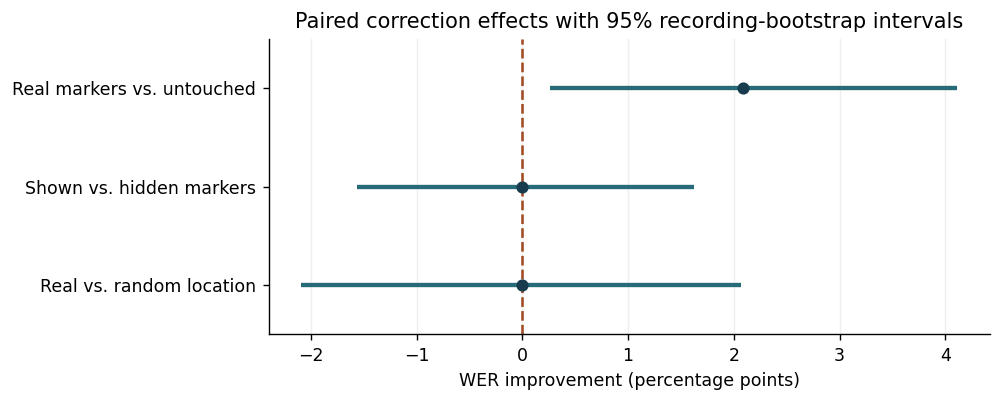

Positive values favor visible real markers. A confidence interval spanning zero allows either direction.


In [77]:
# Use the same eligible recordings when comparing real and randomized editing locations.
if RUN_CORRECTION:
    arm_scores = pd.read_csv(tables / "llm_arm_summary.csv")
    matched = arm_scores.query("group=='dysarthria' and population=='matched'").copy()
    matched["Word errors"] = matched[["S", "D", "I"]].sum(axis=1)
    matched["WER (%)"] = 100 * matched.WER
    print("Dysarthric recordings with a feasible equal-budget random window")
    show(
        matched[["arm", "recordings", "words", "calls", "Word errors", "WER (%)"]].rename(
            columns={
                "arm": "Condition",
                "recordings": "Recordings",
                "words": "Reference words",
                "calls": "Region calls",
            }
        )
    )
    contrasts = pd.read_csv(tables / "paired_correction_contrasts.csv")
    dys = contrasts[contrasts.group.eq("dysarthria")]
    questions = [
        ("marked", "untouched", "visible", "Real markers vs. untouched"),
        ("marked", "hidden", "visible", "Shown vs. hidden markers"),
        ("matched", "random", "visible", "Real vs. random location"),
    ]
    rows = []
    for population, before, after, label_text in questions:
        item = dys[
            (dys.population == population) & (dys.before == before) & (dys.after == after)
        ].iloc[0]
        rows.append(
            {
                "Comparison": label_text,
                "Recordings": item.n,
                "Improved": item.improved,
                "Worsened": item.worsened,
                "Tied": item.tied,
                "Sign p": item.sign_p,
                "Gain": 100 * item.wer_improvement,
                "Low": 100 * item.lo,
                "High": 100 * item.hi,
            }
        )
    effects = pd.DataFrame(rows)
    show(effects[["Comparison", "Recordings", "Improved", "Worsened", "Tied", "Sign p", "Gain", "Low", "High"]])
    fig, ax = plt.subplots(figsize=(7.9, 3.1), layout="constrained")
    for i, row in effects.iterrows():
        if np.isfinite([row.Gain, row.Low, row.High]).all():
            ax.hlines(i, row.Low, row.High, color="#276b78", lw=2.5)
            ax.scatter(row.Gain, i, color="#183b4e", zorder=3)
    ax.axvline(0, ls="--", color="#a34d27")
    ax.set(
        yticks=range(len(rows)),
        yticklabels=effects.Comparison,
        ylim=(2.5, -0.5),
        xlabel="WER improvement (percentage points)",
        title="Paired correction effects with 95% recording-bootstrap intervals",
    )
    ax.grid(axis="x", alpha=0.2)
    draw(fig)
    print(
        "Positive values favor visible real markers. A confidence interval spanning zero allows either direction."
    )
else:
    print("No LLM contrasts in an acoustic-only run.")

<a id="section-9"></a>

## 9. Review the earlier study and save results

The earlier study scored 363 files drawn from training, validation, and test data together. Only 35 were original test files. The table reports those older counts separately because this notebook keeps each recorded take in one group.

**Submitted analysis at 0.30 s.** The abstract combined dysarthric reliability with all-speaker coverage. The table below uses the original candidate screen (an internal hypothesis gap of at least 0.02 s).

| Population | Candidate files / errors | Marked files / markers | Reliability / random | Error coverage / random |
|---|---:|---:|---:|---:|
| Dysarthric | 548 / 1,582 | 362 / 596 | 71.64% / 66.92% | 47.22% / 44.95% |
| All speakers | 570 / 1,617 | 365 / 599 | 71.79% / 67.03% | 46.75% / 44.42% |

Of the 596 dysarthric markers, 447 came from training files, 67 from validation, 55 from test and 27 from one duration-excluded file. The separate multiword-reference utterance analysis counted 356 flagged dysarthric files and 359 flagged files overall. The historical permutation p-value in the threshold table tests reliability.

**Correction flow.** The 365 eligible files generated 370 distinct regional jobs. For sample IDs 11060 and 11997, stripping the markers did not recover the original normalized ASR. Excluding those files left 363 scored files, 253 takes and 368 regions. Across all jobs the unchanged / accepted word change / rejected counts were 281 / 87 / 2. Across scored regions they were 280 / 86 / 2.

The two-sided sign test asks whether improvements and deteriorations are equally frequent among the 42 non-tied files (24 improved, 18 worsened, p = 0.441). It does not test the magnitude of the corpus WER change. Paired microphone files can make these historical file-level signs dependent. The original test subset contained 35 files from 31 takes, 269 reference words and a change from 121 to 120 errors. One improved and 34 tied (p = 1.0).

In [78]:
# Historical figures provide context for the submission. Fresh evaluation never uses them for scoring.
old_rows = [
    dict(
        population="All originally processed",
        files=363, recordings=253, reference_words=2959,
        before=1177,
        after=1169,
        improved=24,
        worsened=18,
        tied=321,
        sign_p=binomtest(24, 42, 0.5).pvalue,
    ),
    dict(
        population="Original test subset",
        files=35, recordings=31, reference_words=269,
        before=121,
        after=120,
        improved=1,
        worsened=0,
        tied=34,
        sign_p=binomtest(1, 1, 0.5).pvalue,
    ),
]
historical = table("submitted_correction_direction", old_rows)
show(
    historical.rename(
        columns={
            "population": "Historical population",
            "files": "Files",
            "before": "Errors before",
            "after": "Errors after",
            "sign_p": "Sign p",
        }
    )
)

# Fixed historical extracts. The source localization rows are in the completed archive
# under submitted_run/threshold_analysis_all_sets.csv. Count files using the
# paper's saved pause and region-job records at the same operating point.
submitted_markers = pd.read_csv(io.StringIO("""population,threshold,candidate_files,candidate_errors,marked_files,markers,reliability,random_reliability,error_coverage,random_coverage,reliability_permutation_p
all,0.3,570,1617,365,599,0.7178631051752922,0.670270394602615,0.4675324675324675,0.4442359307359307,0.0004997501249375
dysarthric,0.3,548,1582,362,596,0.7164429530201343,0.6691554390799358,0.4721871049304678,0.4494671302149178,0.0004997501249375
"""))
table("submitted_marker_populations", submitted_markers)
submitted_flow = [
    dict(stage="eligible", files=365, regions=370, unchanged=281, accepted_word_change=87, rejected=2),
    dict(stage="scored", files=363, regions=368, unchanged=280, accepted_word_change=86, rejected=2),
]
table("submitted_region_flow", submitted_flow)


Historical population,Files,recordings,reference_words,Errors before,Errors after,improved,worsened,tied,Sign p
All originally processed,363,253,2959,1177,1169,24,18,321,0.44
Original test subset,35,31,269,121,120,1,0,34,1.00


,stage,files,regions,unchanged,accepted_word_change,rejected
0,eligible,365,370,281,87,2
1,scored,363,368,280,86,2


<a id="export"></a>

### Save the results as a ZIP

The final steps save the run settings, file checksums, and a list of where to find each result. The ZIP also includes word timings, transcripts, and any editor replies from this run.

In [79]:
# Index each result and export only the new run.
index = {
    "split and adaptation": [
        "split_manifest.csv",
        "split_audit.json",
        "training_summary.json",
        "validation_history.csv",
    ],
    "threshold selection": [
        "threshold_lock.json",
        "tables/threshold_curve.csv",
        "tables/calibration_boundaries.csv",
    ],
    "held-out ASR": ["tables/exact_asr_predictions.csv", "tables/asr_accuracy.csv"],
    "independent timing and common opportunity set": [
        "timed_recordings.json",
        "checkpoints/dual_ctc_*.json",
        "tables/boundary_map.csv",
        "tables/timing_marker_agreement.csv",
        "tables/timing_paired_differences.csv",
    ],
    "coverage and speaker support": [
        "tables/timing_flow.csv",
        "tables/localization.csv",
        "tables/localization_by_speaker.csv",
    ],
    "historical evidence": [
        "tables/submitted_correction_direction.csv", "tables/submitted_marker_populations.csv",
        "tables/submitted_region_flow.csv",
    ],
}
if RUN_CORRECTION:
    index["equal editing budget and exact outcomes"] = [
        "correction_plan.json",
        "tables/correction_budgets.csv",
        "llm_prompts.json",
        "llm_region_responses.json",
        "tables/exact_correction_predictions.csv",
        "tables/correction_error_counts.csv",
        "tables/llm_arm_summary.csv",
        "tables/paired_correction_contrasts.csv",
    ]
write_json(out / "reviewer_evidence.json", index)

In [80]:
# Record which parts of the run finished.
write_json(
    out / "progress.json",
    dict(
        mode=mode,
        stage="complete" if RUN_CORRECTION else "acoustic_only",
        llm_backend=("echo" if SMOKE else "groq") if RUN_CORRECTION else None,
        completed=now(),
        n_evaluation=len(ev),
        scope=eval_part,
    ),
)
if RUN_CORRECTION:
    (out / "last_provider_failure.json").unlink(missing_ok=True)
write_json(
    out / "file_hashes.json",
    {
        p.relative_to(out).as_posix(): sha(p)
        for p in sorted(out.rglob("*"))
        if p.is_file() and p.name != "file_hashes.json" and p.suffix != ".tmp"
    },
)

In [81]:
# Write the ZIP and show where to find each result.
export_zip("" if RUN_CORRECTION else "_acoustic")
show(
    pd.DataFrame(
        [
            {"Research question": issue, "Evidence file": files[0]}
            for issue, files in index.items()
        ]
    )
)

Saved /kaggle/working/iciss_fresh_full_20261112T053554Z_7b6c322ff5.zip


Research question,Evidence file
split and adaptation,split_manifest.csv
threshold selection,threshold_lock.json
held-out ASR,tables/exact_asr_predictions.csv
independent timing and common opportunity set,timed_recordings.json
coverage and speaker support,tables/timing_flow.csv
historical evidence,tables/submitted_correction_direction.csv
equal editing budget and exact outcomes,correction_plan.json


<a id="reporting"></a>

### Read the final results

Before reporting a result, check whether the run used the full test set or the small smoke test. Record the chosen pause length, how many recordings had a marker, and how many had a matching random comparison.

For the published comparison use the full-run files `tables/exact_asr_predictions.csv` and `tables/exact_correction_predictions.csv`. Join them by recording and identify the correction condition by arm. The completed archive includes unchanged predictions, prompts, region replies and window budgets. The eight-recording echo outputs illustrate execution only. Cite a versioned, accessible copy of the prediction archive in the camera-ready paper.

Correction summaries use one minimum-edit path for the substitution, deletion and insertion counts and for MER. The November 9 archive computed correction MER with a different tie-break from its displayed counts. Use WER and the paired WER contrasts for the paper’s conclusions.